In [1]:

import os
from pathlib import Path

ROOT = Path("/kaggle/input")

print("=" * 75)
print("LUNGVISION INTERACTIVE VIEWER — DATASET INVENTORY")
print("=" * 75)

for dataset in sorted(ROOT.iterdir()):
    if not dataset.is_dir():
        continue

    print(f"\nDATASET: {dataset}")

    for current, dirs, files in os.walk(dataset):
        depth = len(Path(current).relative_to(dataset).parts)

        if depth > 3:
            dirs.clear()
            continue

        dirs[:] = sorted(dirs)

        mhd_count = sum(f.endswith(".mhd") for f in files)
        raw_count = sum(
            f.endswith((".raw", ".zraw")) for f in files
        )
        csv_files = [f for f in files if f.endswith(".csv")]
        model_files = [
            f for f in files
            if f.endswith((".pth", ".pt", ".json", ".csv"))
        ]

        if mhd_count or raw_count or csv_files or model_files:
            print(f"\n  Folder: {current}")
            print(f"  MHD: {mhd_count} | RAW/ZRAW: {raw_count}")

            for f in csv_files[:8]:
                print("  CSV:", f)

            for f in [
                f for f in files
                if f.endswith((".pth", ".pt", ".json"))
            ][:8]:
                print("  Artifact:", f)

print("\nINVENTORY COMPLETE")


LUNGVISION INTERACTIVE VIEWER — DATASET INVENTORY

DATASET: /kaggle/input/datasets



  Folder: /kaggle/input/datasets/avc0706/luna16
  MHD: 0 | RAW/ZRAW: 0
  CSV: annotations.csv
  CSV: candidates.csv
  CSV: sampleSubmission.csv

  Folder: /kaggle/input/datasets/avc0706/luna16/candidates_V2
  MHD: 0 | RAW/ZRAW: 0
  CSV: candidates_V2.csv



  Folder: /kaggle/input/datasets/vafaeii/luna16
  MHD: 0 | RAW/ZRAW: 0
  CSV: annotations.csv
  CSV: candidates.csv
  CSV: sampleSubmission.csv

  Folder: /kaggle/input/datasets/vafaeii/luna16/candidates_V2
  MHD: 0 | RAW/ZRAW: 0
  CSV: candidates_V2.csv



INVENTORY COMPLETE


In [2]:

import os
from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/input/datasets")

mhd_files = []
zraw_files = []
raw_files = []
annotation_files = []

for current, dirs, files in os.walk(ROOT):
    for filename in files:
        path = Path(current) / filename
        suffix = path.suffix.lower()

        if suffix == ".mhd":
            mhd_files.append(path)
        elif suffix == ".zraw":
            zraw_files.append(path)
        elif suffix == ".raw":
            raw_files.append(path)
        elif filename.lower() == "annotations.csv":
            annotation_files.append(path)

print("=" * 65)
print("LUNGVISION CT FILE DISCOVERY")
print("=" * 65)

print("MHD files:", len(mhd_files))
print("ZRAW files:", len(zraw_files))
print("RAW files:", len(raw_files))

print("\nMHD files by dataset:")
print(Counter(
    str(p).split("/")[4] if len(p.parts) > 4 else "unknown"
    for p in mhd_files
))

print("\nANNOTATION FILES:")
for p in annotation_files:
    print(p)

print("\nEXAMPLE CT FILES:")
for p in mhd_files[:5]:
    print(p)

print("\nEXAMPLE SEGMENTATION FILES:")
for p in mhd_files:
    if "seg-lungs" in str(p).lower():
        print(p)
        if sum("seg-lungs" in str(x).lower() for x in mhd_files[:mhd_files.index(p)+1]) >= 5:
            break


LUNGVISION CT FILE DISCOVERY
MHD files: 3109
ZRAW files: 1776
RAW files: 1333

MHD files by dataset:
Counter({'vafaeii': 1776, 'avc0706': 1333})

ANNOTATION FILES:
/kaggle/input/datasets/vafaeii/luna16/annotations.csv
/kaggle/input/datasets/vafaeii/luna16/evaluationScript/evaluationScript/annotations/annotations.csv
/kaggle/input/datasets/avc0706/luna16/annotations.csv
/kaggle/input/datasets/avc0706/luna16/evaluationScript/evaluationScript/annotations/annotations.csv

EXAMPLE CT FILES:
/kaggle/input/datasets/vafaeii/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860.mhd
/kaggle/input/datasets/vafaeii/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840553388986847034053.mhd
/kaggle/input/datasets/vafaeii/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208.mhd
/kaggle/input/datasets/vafaeii/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1.14

In [3]:

import numpy as np
import pandas as pd
import SimpleITK as sitk
from pathlib import Path

# Previously verified scan with 12 LUNA16 annotations
SERIES_UID = (
    "1.3.6.1.4.1.14519.5.2.1.6279.6001."
    "176030616406569931557298712518"
)

DATASET_ROOT = Path("/kaggle/input/datasets/vafaeii/luna16")

# Locate original CT and segmentation files
original_matches = [
    p for p in mhd_files
    if p.name == SERIES_UID + ".mhd"
    and "subset" in str(p).lower()
    and "seg-lungs" not in str(p).lower()
    and "vafaeii" in str(p).lower()
]

mask_matches = [
    p for p in mhd_files
    if p.name == SERIES_UID + ".mhd"
    and "seg-lungs" in str(p).lower()
    and "vafaeii" in str(p).lower()
]

assert len(original_matches) == 1, (
    f"Expected one original CT, found {len(original_matches)}"
)
assert len(mask_matches) == 1, (
    f"Expected one segmentation mask, found {len(mask_matches)}"
)

original_ct_path = original_matches[0]
mask_path = mask_matches[0]

print("ORIGINAL CT:", original_ct_path)
print("LUNG MASK:", mask_path)

# Read volumes
ct_image = sitk.ReadImage(str(original_ct_path))
mask_image = sitk.ReadImage(str(mask_path))

correct_ct = sitk.GetArrayFromImage(ct_image)
correct_mask = sitk.GetArrayFromImage(mask_image)

# Read annotations
annotations_path = DATASET_ROOT / "annotations.csv"
annotations_df = pd.read_csv(annotations_path)

selected_annotations = annotations_df[
    annotations_df["seriesuid"] == SERIES_UID
].copy().reset_index(drop=True)

# Geometry verification
geometry_match = (
    ct_image.GetSize() == mask_image.GetSize()
    and ct_image.GetSpacing() == mask_image.GetSpacing()
    and ct_image.GetOrigin() == mask_image.GetOrigin()
    and ct_image.GetDirection() == mask_image.GetDirection()
)

print("\n" + "=" * 60)
print("LUNGVISION CT LOADING REPORT")
print("=" * 60)

print("CT shape (Z,Y,X):", correct_ct.shape)
print("Mask shape (Z,Y,X):", correct_mask.shape)
print("CT intensity range:", correct_ct.min(), correct_ct.max())
print("Mask labels:", np.unique(correct_mask))
print("CT spacing (X,Y,Z):", ct_image.GetSpacing())
print("CT origin:", ct_image.GetOrigin())
print("Geometry identical:", geometry_match)
print("Nodule annotations:", len(selected_annotations))

assert correct_ct.shape == correct_mask.shape
assert geometry_match
assert len(selected_annotations) > 0

print("\nCT AND MASK LOADED SUCCESSFULLY.")


ORIGINAL CT: /kaggle/input/datasets/vafaeii/luna16/subset6/subset6/1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406569931557298712518.mhd
LUNG MASK: /kaggle/input/datasets/vafaeii/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406569931557298712518.mhd



LUNGVISION CT LOADING REPORT
CT shape (Z,Y,X): (253, 512, 512)
Mask shape (Z,Y,X): (253, 512, 512)
CT intensity range: -2048 3071


Mask labels: [0 3 4 5]
CT spacing (X,Y,Z): (0.7421879768371582, 0.7421879768371582, 1.25)
CT origin: (-193.100006, -166.699997, -307.25)
Geometry identical: True
Nodule annotations: 12

CT AND MASK LOADED SUCCESSFULLY.


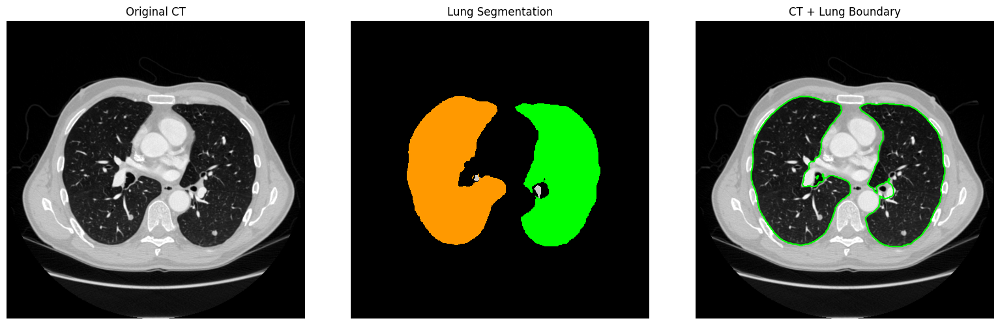

Annotations available: 12


,seriesuid,coordX,coordY,coordZ,diameter_mm
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,107.981511,-4.367357,-124.106848,4.672139
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,71.122115,103.576289,-148.451546,7.046048
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,49.946480,39.217484,-239.834661,12.381023
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,72.370762,83.673704,-244.384788,6.337056
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-35.369030,83.725427,-150.252918,7.025817
5,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-41.690084,-7.144611,-158.718074,7.670740
6,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-33.724506,-17.303540,-103.052988,4.517226
7,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-10.609860,61.082003,-166.535318,4.848113
8,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-33.075740,103.021741,-192.635969,6.450731
9,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-53.331800,96.458558,-226.256517,10.984899


In [4]:

import matplotlib.pyplot as plt

z = correct_ct.shape[0] // 2
ct_slice = correct_ct[z]
mask_slice = correct_mask[z]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(ct_slice, cmap="gray", vmin=-1000, vmax=400)
axes[0].set_title("Original CT")

axes[1].imshow(mask_slice, cmap="nipy_spectral", interpolation="nearest")
axes[1].set_title("Lung Segmentation")

axes[2].imshow(ct_slice, cmap="gray", vmin=-1000, vmax=400)
axes[2].contour(
    np.isin(mask_slice, [3, 4]),
    levels=[0.5],
    colors="lime"
)
axes[2].set_title("CT + Lung Boundary")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Annotations available:", len(selected_annotations))
display(selected_annotations)


In [5]:

import numpy as np
import pandas as pd

mapped_rows = []

for _, row in selected_annotations.iterrows():

    physical_point = (
        float(row["coordX"]),
        float(row["coordY"]),
        float(row["coordZ"])
    )

    # Physical coordinates -> continuous voxel coordinates
    continuous_index = ct_image.TransformPhysicalPointToContinuousIndex(
        physical_point
    )

    # Round to nearest voxel
    voxel_x, voxel_y, voxel_z = [
        int(round(v)) for v in continuous_index
    ]

    inside = (
        0 <= voxel_x < correct_ct.shape[2]
        and 0 <= voxel_y < correct_ct.shape[1]
        and 0 <= voxel_z < correct_ct.shape[0]
    )

    center_label = (
        int(correct_mask[voxel_z, voxel_y, voxel_x])
        if inside else None
    )

    mapped_rows.append({
        "seriesuid": row["seriesuid"],
        "coordX_mm": physical_point[0],
        "coordY_mm": physical_point[1],
        "coordZ_mm": physical_point[2],
        "voxel_x": voxel_x,
        "voxel_y": voxel_y,
        "voxel_z": voxel_z,
        "diameter_mm": float(row["diameter_mm"]),
        "inside_volume": inside,
        "center_label": center_label
    })

mapped_df = pd.DataFrame(mapped_rows)

print("NODULE COORDINATE MAPPING REPORT")
print("=" * 65)
print("Total annotations:", len(mapped_df))
print("Inside CT volume:", mapped_df["inside_volume"].sum())
print("Outside CT volume:", (~mapped_df["inside_volume"]).sum())

display(mapped_df)


NODULE COORDINATE MAPPING REPORT
Total annotations: 12
Inside CT volume: 12
Outside CT volume: 0


,seriesuid,coordX_mm,coordY_mm,coordZ_mm,voxel_x,voxel_y,voxel_z,diameter_mm,inside_volume,center_label
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,107.981511,-4.367357,-124.106848,406,219,147,4.672139,True,3
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,71.122115,103.576289,-148.451546,356,364,127,7.046048,True,3
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,49.946480,39.217484,-239.834661,327,277,54,12.381023,True,3
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,72.370762,83.673704,-244.384788,358,337,50,6.337056,True,3
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-35.369030,83.725427,-150.252918,213,337,126,7.025817,True,4
5,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-41.690084,-7.144611,-158.718074,204,215,119,7.670740,True,4
6,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-33.724506,-17.303540,-103.052988,215,201,163,4.517226,True,4
7,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-10.609860,61.082003,-166.535318,246,307,113,4.848113,True,4
8,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-33.075740,103.021741,-192.635969,216,363,92,6.450731,True,4
9,1.3.6.1.4.1.14519.5.2.1.6279.6001.176030616406...,-53.331800,96.458558,-226.256517,188,355,65,10.984899,True,4


Valid nodules: 12


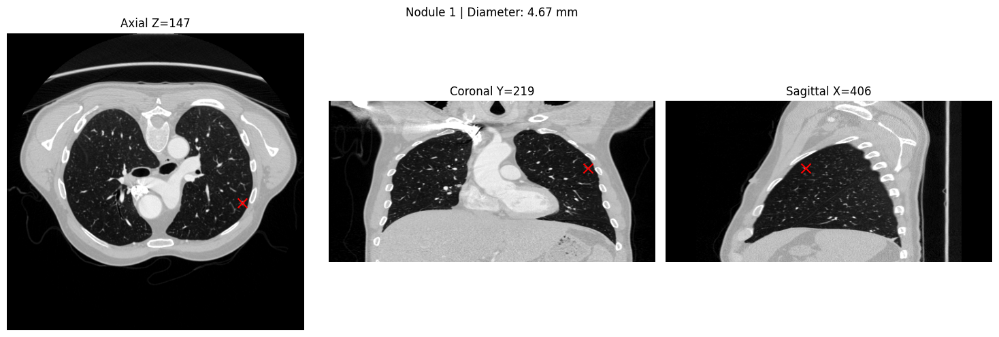

In [6]:

import matplotlib.pyplot as plt

valid_nodules = mapped_df[
    mapped_df["inside_volume"]
].reset_index(drop=True)

print("Valid nodules:", len(valid_nodules))

if len(valid_nodules) > 0:

    selected = valid_nodules.iloc[0]

    x = int(selected["voxel_x"])
    y = int(selected["voxel_y"])
    z = int(selected["voxel_z"])

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Axial
    axes[0].imshow(
        correct_ct[z],
        cmap="gray",
        vmin=-1000,
        vmax=400,
        origin="lower"
    )
    axes[0].scatter(x, y, c="red", marker="x", s=100)
    axes[0].set_title(f"Axial Z={z}")

    # Coronal
    axes[1].imshow(
        correct_ct[:, y, :],
        cmap="gray",
        vmin=-1000,
        vmax=400,
        origin="lower"
    )
    axes[1].scatter(x, z, c="red", marker="x", s=100)
    axes[1].set_title(f"Coronal Y={y}")

    # Sagittal
    axes[2].imshow(
        correct_ct[:, :, x],
        cmap="gray",
        vmin=-1000,
        vmax=400,
        origin="lower"
    )
    axes[2].scatter(y, z, c="red", marker="x", s=100)
    axes[2].set_title(f"Sagittal X={x}")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"Nodule 1 | Diameter: {selected['diameter_mm']:.2f} mm"
    )
    plt.tight_layout()
    plt.show()


In [7]:

import numpy as np
import plotly.graph_objects as go
from skimage.measure import marching_cubes

# Downsample only for visualization, not for annotation calculations
STEP = 2

mask_small = correct_mask[::STEP, ::STEP, ::STEP]

# Convert voxel coordinates to physical millimetres
origin = np.asarray(ct_image.GetOrigin(), dtype=float)
spacing = np.asarray(ct_image.GetSpacing(), dtype=float)
direction = np.asarray(
    ct_image.GetDirection(), dtype=float
).reshape(3, 3)

def voxel_zyx_to_physical(vertices):
    # Marching cubes returns Z, Y, X
    indices_xyz = vertices[:, [2, 1, 0]] * STEP

    physical = (
        origin +
        (direction @ (indices_xyz * spacing).T).T
    )

    return physical

fig_3d = go.Figure()

lung_colors = {
    3: "royalblue",
    4: "orange"
}

# Extract both lung surfaces
for label, color in lung_colors.items():

    binary_mask = (mask_small == label).astype(np.uint8)

    vertices, faces, normals, values = marching_cubes(
        binary_mask,
        level=0.5,
        step_size=1
    )

    physical_vertices = voxel_zyx_to_physical(vertices)

    fig_3d.add_trace(
        go.Mesh3d(
            x=physical_vertices[:, 0],
            y=physical_vertices[:, 1],
            z=physical_vertices[:, 2],
            i=faces[:, 0],
            j=faces[:, 1],
            k=faces[:, 2],
            color=color,
            opacity=0.55,
            name=f"Lung label {label}",
            hoverinfo="name"
        )
    )

# Add all annotated nodule centres
nodule_colors = [
    "red" if label in [3, 4] else "magenta"
    for label in mapped_df["center_label"]
]

fig_3d.add_trace(
    go.Scatter3d(
        x=mapped_df["coordX_mm"],
        y=mapped_df["coordY_mm"],
        z=mapped_df["coordZ_mm"],
        mode="markers+text",
        text=[f"Nodule {i+1}" for i in range(len(mapped_df))],
        textposition="top center",
        marker=dict(
            size=6,
            color=nodule_colors,
            line=dict(color="white", width=1)
        ),
        customdata=np.column_stack([
            mapped_df["diameter_mm"],
            mapped_df["center_label"]
        ]),
        hovertemplate=(
            "<b>%{text}</b><br>"
            "X: %{x:.2f} mm<br>"
            "Y: %{y:.2f} mm<br>"
            "Z: %{z:.2f} mm<br>"
            "Diameter: %{customdata[0]:.2f} mm<br>"
            "Centre label: %{customdata[1]}<extra></extra>"
        ),
        name="Nodule annotations"
    )
)

fig_3d.update_layout(
    title="LungVision AI — 3D Lungs with Nodule Annotations",
    scene=dict(
        xaxis_title="X (mm)",
        yaxis_title="Y (mm)",
        zaxis_title="Z (mm)",
        aspectmode="data"
    ),
    width=1000,
    height=750,
    margin=dict(l=0, r=0, t=60, b=0)
)

fig_3d.show()

print("3D RECONSTRUCTION COMPLETE")
print("Lung surfaces:", 2)
print("Nodule markers:", len(mapped_df))
print("Voxel downsampling factor:", STEP)


3D RECONSTRUCTION COMPLETE
Lung surfaces: 2
Nodule markers: 12
Voxel downsampling factor: 2


In [8]:

import plotly
import plotly.io as pio
from IPython.display import display

print("Plotly version:", plotly.__version__)
print("Default renderer:", pio.renderers.default)
print("Number of traces:", len(fig_3d.data))

for i, trace in enumerate(fig_3d.data):
    print(
        f"Trace {i}: {trace.type} | "
        f"Name: {trace.name}"
    )

    if trace.type == "mesh3d":
        print("  Vertices:", len(trace.x))
        print("  Faces:", len(trace.i))

    elif trace.type == "scatter3d":
        print("  Markers:", len(trace.x))

print("\nFigure dimensions:", fig_3d.layout.width, fig_3d.layout.height)

# Test a lightweight interactive Plotly figure
test_fig = go.Figure(
    data=[
        go.Scatter3d(
            x=[0, 1, 2],
            y=[0, 1, 0],
            z=[0, 2, 1],
            mode="markers+lines",
            marker=dict(size=8)
        )
    ]
)

test_fig.update_layout(
    title="LungVision Plotly Rendering Test",
    height=450
)

display(test_fig)


Plotly version: 5.24.1
Default renderer: colab
Number of traces: 3
Trace 0: mesh3d | Name: Lung label 3
  Vertices: 65585
  Faces: 131206
Trace 1: mesh3d | Name: Lung label 4
  Vertices: 65562
  Faces: 131200
Trace 2: scatter3d | Name: Nodule annotations
  Markers: 12

Figure dimensions: 1000 750


In [9]:

import numpy as np
import plotly.graph_objects as go
from skimage.measure import marching_cubes
from IPython.display import display

# Visualization-only downsampling
VOLUME_STEP = 2
MESH_STEP = 3

mask_small = correct_mask[
    ::VOLUME_STEP,
    ::VOLUME_STEP,
    ::VOLUME_STEP
]

origin = np.asarray(ct_image.GetOrigin(), dtype=float)
spacing = np.asarray(ct_image.GetSpacing(), dtype=float)
direction = np.asarray(
    ct_image.GetDirection(), dtype=float
).reshape(3, 3)

def voxel_zyx_to_physical(vertices):
    indices_xyz = vertices[:, [2, 1, 0]] * VOLUME_STEP
    return origin + (
        direction @ (indices_xyz * spacing).T
    ).T

fig_3d_light = go.Figure()

for label, color in [(3, "royalblue"), (4, "orange")]:

    binary_mask = (mask_small == label).astype(np.uint8)

    vertices, faces, _, _ = marching_cubes(
        binary_mask,
        level=0.5,
        step_size=MESH_STEP
    )

    points = voxel_zyx_to_physical(vertices)

    fig_3d_light.add_trace(
        go.Mesh3d(
            x=points[:, 0],
            y=points[:, 1],
            z=points[:, 2],
            i=faces[:, 0],
            j=faces[:, 1],
            k=faces[:, 2],
            color=color,
            opacity=0.65,
            flatshading=False,
            name=f"Lung {label}",
            hoverinfo="name"
        )
    )

# Add nodule centres
fig_3d_light.add_trace(
    go.Scatter3d(
        x=mapped_df["coordX_mm"],
        y=mapped_df["coordY_mm"],
        z=mapped_df["coordZ_mm"],
        mode="markers",
        marker=dict(
            size=5,
            color="red",
            line=dict(width=1, color="white")
        ),
        customdata=np.column_stack([
            mapped_df["diameter_mm"],
            mapped_df["center_label"]
        ]),
        hovertemplate=(
            "Nodule<br>"
            "Diameter: %{customdata[0]:.2f} mm<br>"
            "Centre label: %{customdata[1]}<extra></extra>"
        ),
        name="Nodule annotations"
    )
)

fig_3d_light.update_layout(
    title="LungVision AI — Interactive 3D Lung Reconstruction",
    width=900,
    height=650,
    margin=dict(l=0, r=0, t=55, b=0),
    scene=dict(
        xaxis_title="X (mm)",
        yaxis_title="Y (mm)",
        zaxis_title="Z (mm)",
        aspectmode="data"
    )
)

print("OPTIMIZED 3D MODEL")
for trace in fig_3d_light.data:
    print(
        trace.name,
        "| vertices/markers:", len(trace.x),
        "| faces:", len(trace.i) if trace.type == "mesh3d" else "N/A"
    )

display(fig_3d_light)


OPTIMIZED 3D MODEL
Lung 3 | vertices/markers: 7171 | faces: 14374
Lung 4 | vertices/markers: 7131 | faces: 14314
Nodule annotations | vertices/markers: 12 | faces: N/A


In [10]:

from pathlib import Path

output_path = Path(
    "/kaggle/working/lungvision_3d_lungs.html"
)

fig_3d_light.write_html(
    str(output_path),
    include_plotlyjs=True,
    full_html=True
)

print("HTML exported:", output_path)
print("File size MB:", round(output_path.stat().st_size / 1024**2, 2))


HTML exported: /kaggle/working/lungvision_3d_lungs.html
File size MB: 5.37


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
import plotly.graph_objects as go

from IPython.display import display, clear_output

# Physical voxel spacing
sx, sy, sz = ct_image.GetSpacing()

# Dashboard controls
nodule_dropdown = widgets.Dropdown(
    options=[
        (f"Nodule {i+1} — {row.diameter_mm:.2f} mm", i)
        for i, row in mapped_df.iterrows()
    ],
    value=0,
    description="Nodule:",
    layout=widgets.Layout(width="350px")
)

z_control = widgets.IntSlider(
    min=0, max=correct_ct.shape[0]-1,
    value=int(mapped_df.iloc[0]["voxel_z"]),
    description="Axial Z",
    continuous_update=False
)

y_control = widgets.IntSlider(
    min=0, max=correct_ct.shape[1]-1,
    value=int(mapped_df.iloc[0]["voxel_y"]),
    description="Coronal Y",
    continuous_update=False
)

x_control = widgets.IntSlider(
    min=0, max=correct_ct.shape[2]-1,
    value=int(mapped_df.iloc[0]["voxel_x"]),
    description="Sagittal X",
    continuous_update=False
)

# Four visualization panels
axial_out = widgets.Output()
coronal_out = widgets.Output()
sagittal_out = widgets.Output()
model_out = widgets.Output()

# Prevent repeated redraw while dropdown updates sliders
dashboard_state = {"updating": False}


def draw_ct_views(z, y, x, index):

    row = mapped_df.iloc[index]

    nx = int(row["voxel_x"])
    ny = int(row["voxel_y"])
    nz = int(row["voxel_z"])

    # Axial
    with axial_out:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(5, 4))

        ax.imshow(
            correct_ct[z],
            cmap="gray",
            vmin=-1000,
            vmax=400,
            origin="lower"
        )

        ax.contour(
            np.isin(correct_mask[z], [3, 4]),
            levels=[0.5],
            colors="lime",
            linewidths=0.8,
            origin="lower"
        )

        ax.scatter(nx, ny, c="red", marker="x", s=100)
        ax.axhline(y, color="cyan", linewidth=0.6)
        ax.axvline(x, color="cyan", linewidth=0.6)

        ax.set_title(f"Axial | Z={z}")
        ax.axis("off")

        plt.tight_layout()
        plt.show()
        plt.close(fig)

    # Coronal
    with coronal_out:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(5, 4))

        ax.imshow(
            correct_ct[:, y, :],
            cmap="gray",
            vmin=-1000,
            vmax=400,
            origin="lower",
            aspect=sz/sx
        )

        ax.contour(
            np.isin(correct_mask[:, y, :], [3, 4]),
            levels=[0.5],
            colors="lime",
            linewidths=0.8,
            origin="lower"
        )

        ax.scatter(nx, nz, c="red", marker="x", s=100)
        ax.axhline(z, color="cyan", linewidth=0.6)
        ax.axvline(x, color="cyan", linewidth=0.6)

        ax.set_title(f"Coronal | Y={y}")
        ax.axis("off")

        plt.tight_layout()
        plt.show()
        plt.close(fig)

    # Sagittal
    with sagittal_out:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(5, 4))

        ax.imshow(
            correct_ct[:, :, x],
            cmap="gray",
            vmin=-1000,
            vmax=400,
            origin="lower",
            aspect=sz/sy
        )

        ax.contour(
            np.isin(correct_mask[:, :, x], [3, 4]),
            levels=[0.5],
            colors="lime",
            linewidths=0.8,
            origin="lower"
        )

        ax.scatter(ny, nz, c="red", marker="x", s=100)
        ax.axhline(z, color="cyan", linewidth=0.6)
        ax.axvline(y, color="cyan", linewidth=0.6)

        ax.set_title(f"Sagittal | X={x}")
        ax.axis("off")

        plt.tight_layout()
        plt.show()
        plt.close(fig)


def draw_3d(index):

    row = mapped_df.iloc[index]

    with model_out:
        clear_output(wait=True)

        fig = go.Figure(
            data=list(fig_3d_light.data[:2])
        )

        # All nodule markers
        fig.add_trace(
            go.Scatter3d(
                x=mapped_df["coordX_mm"],
                y=mapped_df["coordY_mm"],
                z=mapped_df["coordZ_mm"],
                mode="markers",
                marker=dict(
                    size=4,
                    color="red",
                    opacity=0.75
                ),
                name="All nodules"
            )
        )

        # Highlight selected nodule
        fig.add_trace(
            go.Scatter3d(
                x=[row["coordX_mm"]],
                y=[row["coordY_mm"]],
                z=[row["coordZ_mm"]],
                mode="markers+text",
                text=[f"Nodule {index+1}"],
                textposition="top center",
                marker=dict(
                    size=10,
                    color="yellow",
                    symbol="diamond",
                    line=dict(color="black", width=2)
                ),
                name="Selected nodule"
            )
        )

        fig.update_layout(
            title=f"3D Lung Model | Nodule {index+1}",
            height=480,
            margin=dict(l=0, r=0, t=45, b=0),
            scene=dict(
                xaxis_title="X (mm)",
                yaxis_title="Y (mm)",
                zaxis_title="Z (mm)",
                aspectmode="data"
            )
        )

        display(fig)


def refresh_dashboard():

    z = z_control.value
    y = y_control.value
    x = x_control.value
    index = nodule_dropdown.value

    draw_ct_views(z, y, x, index)
    draw_3d(index)

    row = mapped_df.iloc[index]

    print(
        f"Selected Nodule: {index+1} | "
        f"Diameter: {row['diameter_mm']:.2f} mm | "
        f"Voxel: ({int(row['voxel_x'])}, "
        f"{int(row['voxel_y'])}, "
        f"{int(row['voxel_z'])}) | "
        f"Centre label: {int(row['center_label'])}"
    )


def on_nodule_change(change):

    if change["name"] != "value":
        return

    if dashboard_state["updating"]:
        return

    dashboard_state["updating"] = True

    try:
        row = mapped_df.iloc[change["new"]]

        z_control.value = int(row["voxel_z"])
        y_control.value = int(row["voxel_y"])
        x_control.value = int(row["voxel_x"])

    finally:
        dashboard_state["updating"] = False

    refresh_dashboard()


def on_slice_change(change):

    if change["name"] != "value":
        return

    if not dashboard_state["updating"]:
        refresh_dashboard()


nodule_dropdown.observe(on_nodule_change, names="value")

for control in [z_control, y_control, x_control]:
    control.observe(on_slice_change, names="value")


# Dashboard layout
controls = widgets.VBox([
    nodule_dropdown,
    z_control,
    y_control,
    x_control
])

top_row = widgets.HBox([
    axial_out,
    coronal_out
])

bottom_row = widgets.HBox([
    sagittal_out,
    model_out
])

dashboard = widgets.VBox([
    widgets.HTML(
        "<h2 style='color:#2563eb'>"
        "LungVision AI — Interactive CT Workstation"
        "</h2>"
        "<p>Multiplanar CT reconstruction and 3D lung visualization</p>"
    ),
    controls,
    top_row,
    bottom_row
])

display(dashboard)

# Initial rendering
refresh_dashboard()

print("LUNGVISION UNIFIED VIEWER INITIALIZED")


In [ ]:

# =========================================================
# LUNGVISION — KAGGLE COMPATIBLE SYNCHRONIZED 3D VIEWER
# Uses go.Figure instead of go.FigureWidget
# =========================================================

import ipywidgets as widgets
import plotly.graph_objects as go
import numpy as np
from IPython.display import display, clear_output

print("Initializing Kaggle-compatible viewer...")

# ---------------------------------------------------------

# ---------------------------------------------------------
# 0. COORDINATE GRIDS, CT VOLUME & 3D MODEL PREPARATION
# ---------------------------------------------------------

ct = correct_ct
Z, Y, X = ct.shape
nodules = mapped_df

origin = np.asarray(ct_image.GetOrigin(), dtype=float)
spacing = np.asarray(ct_image.GetSpacing(), dtype=float)

x_coords = origin[0] + np.arange(X) * spacing[0]
y_coords = origin[1] + np.arange(Y) * spacing[1]
z_coords = origin[2] + np.arange(Z) * spacing[2]

# 3D lung surfaces and nodule markers from earlier reconstruction
lung_traces = list(fig_3d_light.data[:2])
marker_trace = (
    fig_3d_light.data[2]
    if len(fig_3d_light.data) > 2
    else go.Scatter3d(
        x=mapped_df["coordX_mm"],
        y=mapped_df["coordY_mm"],
        z=mapped_df["coordZ_mm"],
        mode="markers",
        marker=dict(size=4, color="red", opacity=0.75),
        name="All nodules",
    )
)

def get_axial(z_idx):
    xx, yy = np.meshgrid(x_coords, y_coords)
    zz = np.full_like(xx, z_coords[z_idx])
    image = ct[z_idx, :, :]
    return xx, yy, zz, image

def get_coronal(y_idx):
    xx, zz = np.meshgrid(x_coords, z_coords)
    yy = np.full_like(xx, y_coords[y_idx])
    image = ct[:, y_idx, :]
    return xx, yy, zz, image

def get_sagittal(x_idx):
    yy, zz = np.meshgrid(y_coords, z_coords)
    xx = np.full_like(yy, x_coords[x_idx])
    image = ct[:, :, x_idx]
    return xx, yy, zz, image

# 1. INITIAL POSITIONS
# ---------------------------------------------------------

initial_z = Z // 2
initial_y = Y // 2
initial_x = X // 2

# ---------------------------------------------------------
# 2. SLIDERS
# ---------------------------------------------------------

axial_slider = widgets.IntSlider(
    value=initial_z,
    min=0,
    max=Z - 1,
    description="Axial Z",
    continuous_update=False,
    layout=widgets.Layout(width="500px")
)

coronal_slider = widgets.IntSlider(
    value=initial_y,
    min=0,
    max=Y - 1,
    description="Coronal Y",
    continuous_update=False,
    layout=widgets.Layout(width="500px")
)

sagittal_slider = widgets.IntSlider(
    value=initial_x,
    min=0,
    max=X - 1,
    description="Sagittal X",
    continuous_update=False,
    layout=widgets.Layout(width="500px")
)

status = widgets.HTML()

plot_output = widgets.Output(
    layout=widgets.Layout(width="100%")
)

# ---------------------------------------------------------
# 3. BUILD FIGURE FOR CURRENT SLIDER POSITIONS
# ---------------------------------------------------------

def build_synced_figure(z, y, x):

    fig = go.Figure()

    # Lung surfaces
    for trace in lung_traces:
        fig.add_trace(trace)

    # Axial plane
    xx, yy, zz, image = get_axial(z)

    fig.add_trace(go.Surface(
        x=xx,
        y=yy,
        z=zz,
        surfacecolor=np.clip(image, -1000, 400),
        colorscale="Gray",
        cmin=-1000,
        cmax=400,
        opacity=0.85,
        showscale=False,
        name="Axial plane",
        hoverinfo="skip"
    ))

    # Coronal plane
    xx, yy, zz, image = get_coronal(y)

    fig.add_trace(go.Surface(
        x=xx,
        y=yy,
        z=zz,
        surfacecolor=np.clip(image, -1000, 400),
        colorscale="Gray",
        cmin=-1000,
        cmax=400,
        opacity=0.85,
        showscale=False,
        name="Coronal plane",
        hoverinfo="skip"
    ))

    # Sagittal plane
    xx, yy, zz, image = get_sagittal(x)

    fig.add_trace(go.Surface(
        x=xx,
        y=yy,
        z=zz,
        surfacecolor=np.clip(image, -1000, 400),
        colorscale="Gray",
        cmin=-1000,
        cmax=400,
        opacity=0.85,
        showscale=False,
        name="Sagittal plane",
        hoverinfo="skip"
    ))

    # Nodule markers
    fig.add_trace(marker_trace)

    # Crosshair intersection
    fig.add_trace(go.Scatter3d(
        x=[x_coords[x]],
        y=[y_coords[y]],
        z=[z_coords[z]],
        mode="markers",
        marker=dict(
            size=7,
            color="lime",
            symbol="diamond",
            line=dict(color="black", width=1)
        ),
        name="Plane intersection"
    ))

    fig.update_layout(
        title="LungVision AI — Synchronized 3D CT Viewer",
        width=1100,
        height=800,
        scene=dict(
            xaxis_title="X (mm)",
            yaxis_title="Y (mm)",
            zaxis_title="Z (mm)",
            aspectmode="data",
            camera=dict(
                eye=dict(x=1.6, y=1.6, z=1.3)
            )
        ),
        margin=dict(l=0, r=0, t=50, b=0),
        legend=dict(x=0.01, y=0.99)
    )

    return fig

# ---------------------------------------------------------
# 4. REFRESH FIGURE
# ---------------------------------------------------------

def update_view(change=None):

    z = axial_slider.value
    y = coronal_slider.value
    x = sagittal_slider.value

    status.value = (
        f"<b>Current CT position:</b> "
        f"X={x}, Y={y}, Z={z}<br>"
        f"<b>Physical coordinates:</b> "
        f"X={x_coords[x]:.2f} mm, "
        f"Y={y_coords[y]:.2f} mm, "
        f"Z={z_coords[z]:.2f} mm"
    )

    fig = build_synced_figure(z, y, x)

    with plot_output:
        clear_output(wait=True)
        display(fig)

# ---------------------------------------------------------
# 5. CONNECT SLIDERS
# ---------------------------------------------------------

axial_slider.observe(update_view, names="value")
coronal_slider.observe(update_view, names="value")
sagittal_slider.observe(update_view, names="value")

# ---------------------------------------------------------
# 6. DISPLAY
# ---------------------------------------------------------

controls = widgets.VBox([
    widgets.HTML(
        "<h3>LungVision — Interactive 3D CT Workstation</h3>"
        "<p>Move the sliders to navigate through the CT volume.</p>"
    ),
    axial_slider,
    coronal_slider,
    sagittal_slider,
    status
])

display(controls)
display(plot_output)

update_view()

print("\nKAGGLE-COMPATIBLE VIEWER INITIALIZED")
print("Lung surfaces:", len(lung_traces))
print("Nodule markers:", len(nodules))
print("CT dimensions:", ct.shape)


In [ ]:

# =========================================================
# LUNGVISION — 3D VIEWER VISUAL IMPROVEMENTS
# =========================================================
import numpy as np
import plotly.graph_objects as go

def build_synced_figure(z, y, x):

    fig = go.Figure()

    # Lung surfaces with improved transparency
    for trace in lung_traces:
        updated_trace = trace.to_plotly_json()
        updated_trace["opacity"] = 0.65
        fig.add_trace(go.Mesh3d(updated_trace))

    # Axial plane
    xx, yy, zz, image = get_axial(z)

    fig.add_trace(go.Surface(
        x=xx, y=yy, z=zz,
        surfacecolor=np.clip(image, -1000, 400),
        colorscale="Gray",
        cmin=-1000, cmax=400,
        opacity=0.38,
        showscale=False,
        name="Axial CT",
        hoverinfo="skip"
    ))

    # Coronal plane
    xx, yy, zz, image = get_coronal(y)

    fig.add_trace(go.Surface(
        x=xx, y=yy, z=zz,
        surfacecolor=np.clip(image, -1000, 400),
        colorscale="Gray",
        cmin=-1000, cmax=400,
        opacity=0.38,
        showscale=False,
        name="Coronal CT",
        hoverinfo="skip"
    ))

    # Sagittal plane
    xx, yy, zz, image = get_sagittal(x)

    fig.add_trace(go.Surface(
        x=xx, y=yy, z=zz,
        surfacecolor=np.clip(image, -1000, 400),
        colorscale="Gray",
        cmin=-1000, cmax=400,
        opacity=0.38,
        showscale=False,
        name="Sagittal CT",
        hoverinfo="skip"
    ))

    # Nodule annotations
    fig.add_trace(marker_trace)

    # Intersection of three planes
    fig.add_trace(go.Scatter3d(
        x=[x_coords[x]],
        y=[y_coords[y]],
        z=[z_coords[z]],
        mode="markers",
        marker=dict(
            size=8,
            color="lime",
            symbol="diamond",
            line=dict(color="black", width=1)
        ),
        name="Plane intersection"
    ))

    fig.update_layout(
        title="LungVision AI — Interactive 3D CT Workstation",
        autosize=False,
        width=1350,
        height=950,
        scene=dict(
            xaxis_title="X (mm)",
            yaxis_title="Y (mm)",
            zaxis_title="Z (mm)",
            aspectmode="data",
            camera=dict(
                eye=dict(x=1.7, y=1.7, z=1.4)
            )
        ),
        margin=dict(l=20, r=20, t=70, b=20),
        legend=dict(x=0.01, y=0.99)
    )

    return fig


# Refresh the existing viewer
update_view()

print("3D visualization improved.")
print("Lung transparency: 65% opacity")
print("CT plane transparency: 38% opacity")


In [ ]:

# =========================================================
# LUNGVISION — 3D VIEWER RENDERING FIX
# =========================================================

import ipywidgets as widgets
import plotly.graph_objects as go
from IPython.display import display, clear_output

viewer_output = widgets.Output()

viewer_status = widgets.HTML()

def refresh_lungvision(change=None):

    z = axial_slider.value
    y = coronal_slider.value
    x = sagittal_slider.value

    viewer_status.value = (
        f"<b>Selected coordinates:</b> "
        f"X={x}, Y={y}, Z={z} | "
        f"Physical: ({x_coords[x]:.2f}, "
        f"{y_coords[y]:.2f}, "
        f"{z_coords[z]:.2f}) mm"
    )

    new_figure = build_synced_figure(z, y, x)

    with viewer_output:
        clear_output(wait=True)
        display(new_figure)

# Disconnect previous callbacks
axial_slider.unobserve(update_view, names="value")
coronal_slider.unobserve(update_view, names="value")
sagittal_slider.unobserve(update_view, names="value")

# Connect fresh callbacks
axial_slider.observe(refresh_lungvision, names="value")
coronal_slider.observe(refresh_lungvision, names="value")
sagittal_slider.observe(refresh_lungvision, names="value")

# Display fresh viewer
display(widgets.VBox([
    widgets.HTML("<h3>LungVision — 3D CT Workstation</h3>"),
    axial_slider,
    coronal_slider,
    sagittal_slider,
    viewer_status
]))

display(viewer_output)

# Initial rendering
refresh_lungvision()

print("Viewer rendering requested successfully.")


In [ ]:

from IPython.display import display
import plotly.io as pio

print("Plotly version:", go.__version__ if hasattr(go, "__version__") else "Loaded")
print("Renderer:", pio.renderers.default)

test_fig = build_synced_figure(
    axial_slider.value,
    coronal_slider.value,
    sagittal_slider.value
)

test_fig.update_layout(
    width=1000,
    height=750,
    title="LungVision — Direct Plotly Rendering Test"
)

display(test_fig)

print("Figure traces:", len(test_fig.data))
print("Figure rendered directly.")


In [ ]:

# =========================================================
# LUNGVISION — LIVE 3D FIGURE UPDATE
# Kaggle-compatible display handle approach
# =========================================================

from IPython.display import display
import ipywidgets as widgets

print("Initializing live 3D updates...")

# Remove old slider callbacks
for slider in [axial_slider, coronal_slider, sagittal_slider]:
    try:
        slider.unobserve(refresh_lungvision, names="value")
    except:
        pass

    try:
        slider.unobserve(update_view, names="value")
    except:
        pass

# Build initial figure
initial_figure = build_synced_figure(
    axial_slider.value,
    coronal_slider.value,
    sagittal_slider.value
)

# Display controls
status_live = widgets.HTML()

display(widgets.VBox([
    widgets.HTML(
        "<h3>LungVision — Live Synchronized 3D Workstation</h3>"
    ),
    axial_slider,
    coronal_slider,
    sagittal_slider,
    status_live
]))

# Display figure using a persistent display handle
figure_handle = display(
    initial_figure,
    display_id=True
)

# Slider callback
def live_update(change=None):

    z = axial_slider.value
    y = coronal_slider.value
    x = sagittal_slider.value

    status_live.value = (
        f"<b>Selected voxel:</b> "
        f"X={x}, Y={y}, Z={z}<br>"
        f"<b>Physical position:</b> "
        f"X={x_coords[x]:.2f} mm | "
        f"Y={y_coords[y]:.2f} mm | "
        f"Z={z_coords[z]:.2f} mm"
    )

    updated_figure = build_synced_figure(z, y, x)

    figure_handle.update(updated_figure)

# Register new callbacks
axial_slider.observe(live_update, names="value")
coronal_slider.observe(live_update, names="value")
sagittal_slider.observe(live_update, names="value")

live_update()

print("LIVE 3D VIEWER READY")


In [ ]:
print("CURRENT FIGURE TRACE AUDIT")
print("=" * 60)

for i, trace in enumerate(fig.data):
    print(
        f"Trace {i} | "
        f"Name: {trace.name} | "
        f"Type: {trace.type} | "
        f"Opacity: {trace.opacity}"
    )

In [ ]:

# LUNGVISION — 3D VISUALIZATION IMPROVEMENT

# 1. Make lung surfaces prominent
fig.data[0].update(
    color="#1769E0",
    opacity=0.88,
    flatshading=False
)

fig.data[1].update(
    color="#F59E0B",
    opacity=0.88,
    flatshading=False
)

# 2. Make CT planes subtle
for i in [2, 3, 4]:
    fig.data[i].update(opacity=0.12)

# 3. Improve nodule visibility
fig.data[5].update(
    marker=dict(
        size=6,
        color="#FF2020",
        opacity=1,
        line=dict(color="white", width=1)
    )
)

# 4. Improve overall layout
fig.update_layout(
    title="LungVision AI — Enhanced 3D CT Reconstruction",
    width=1100,
    height=850,
    scene=dict(
        aspectmode="data",
        bgcolor="white"
    ),
    margin=dict(l=10, r=10, t=60, b=10)
)

fig.show()

print("VISUALIZATION UPDATE COMPLETE")
print("Lung opacity: 0.88")
print("CT plane opacity: 0.12")
print("Nodule markers: Enhanced")


In [ ]:

# LUNGVISION — 3D CAMERA AND DISPLAY OPTIMIZATION

fig.update_layout(
    width=1100,
    height=850,
    autosize=False,
    margin=dict(l=0, r=0, t=55, b=0),
    scene=dict(
        aspectmode="cube",
        camera=dict(
            eye=dict(x=1.7, y=1.7, z=1.35),
            center=dict(x=0, y=0, z=0),
            up=dict(x=0, y=0, z=1)
        ),
        bgcolor="white",
        xaxis=dict(title="X (mm)", showbackground=True),
        yaxis=dict(title="Y (mm)", showbackground=True),
        zaxis=dict(title="Z (mm)", showbackground=True)
    )
)

fig.show()

print("3D CAMERA OPTIMIZATION COMPLETE")



In [ ]:

import numpy as np
import pandas as pd

print("=" * 65)
print("LUNGVISION — QUANTITATIVE LUNG VOLUME ANALYSIS")
print("=" * 65)

# Verify array and geometry consistency
assert correct_ct.shape == correct_mask.shape
assert ct_image.GetSize() == mask_image.GetSize()
assert ct_image.GetSpacing() == mask_image.GetSpacing()

# Physical voxel volume
sx, sy, sz = ct_image.GetSpacing()

voxel_volume_mm3 = sx * sy * sz
voxel_volume_ml = voxel_volume_mm3 / 1000

# Use full-resolution segmentation
mask_array = correct_mask

results = []

for label, name in [(3, "Lung 3"), (4, "Lung 4")]:
    voxel_count = int(np.count_nonzero(mask_array == label))

    volume_mm3 = voxel_count * voxel_volume_mm3
    volume_ml = volume_mm3 / 1000

    results.append({
        "Lung": name,
        "Voxels": voxel_count,
        "Volume_mm3": round(volume_mm3, 2),
        "Volume_ml": round(volume_ml, 2)
    })

df_volume = pd.DataFrame(results)

print("\nINDIVIDUAL LUNG VOLUMES")
display(df_volume)

total_voxels = sum(row["Voxels"] for row in results)
total_volume_ml = total_voxels * voxel_volume_ml

print("\nTOTAL SEGMENTED LUNG VOLUME")
print(f"Total voxels: {total_voxels:,}")
print(f"Physical voxel volume: {voxel_volume_mm3:.6f} mm³")
print(f"Total lung volume: {total_volume_ml:.2f} ml")

print("\nALL SEGMENTATION LABELS")
for label in np.unique(mask_array):
    count = int(np.count_nonzero(mask_array == label))
    print(f"Label {label}: {count:,} voxels")

print("\nGEOMETRY VALIDATION: PASSED")
print("FULL-RESOLUTION VOLUME ANALYSIS: COMPLETE")


In [ ]:

import numpy as np
import pandas as pd

print("=" * 65)
print("LUNGVISION — FULL SEGMENTATION LABEL AUDIT")
print("=" * 65)

sx, sy, sz = ct_image.GetSpacing()
voxel_ml = (sx * sy * sz) / 1000

total = correct_mask.size
audit = []

for label in np.unique(correct_mask):
    count = int(np.count_nonzero(correct_mask == label))

    audit.append({
        "Label": int(label),
        "Voxel_Count": count,
        "Percentage": round(100 * count / total, 4),
        "Volume_ml": round(count * voxel_ml, 2)
    })

df_audit = pd.DataFrame(audit)

display(df_audit)

print("\nVALIDATION CHECKS")
print("Total voxels:", f"{total:,}")
print("Count sum:", f"{df_audit['Voxel_Count'].sum():,}")
print("Counts reconcile:",
      int(df_audit["Voxel_Count"].sum()) == total)

lung3 = int(np.count_nonzero(correct_mask == 3))
lung4 = int(np.count_nonzero(correct_mask == 4))
label5 = int(np.count_nonzero(correct_mask == 5))

print("\nLUNG BALANCE")
print(f"Lung 3: {lung3 * voxel_ml:.2f} ml")
print(f"Lung 4: {lung4 * voxel_ml:.2f} ml")
print(f"Absolute difference: {abs(lung3-lung4)*voxel_ml:.2f} ml")
print(f"Relative difference: {abs(lung3-lung4)/min(lung3,lung4)*100:.2f}%")

print("\nLABEL 5 — SEPARATE AUDIT")
print(f"Voxels: {label5:,}")
print(f"Volume: {label5 * voxel_ml:.2f} ml")
print("Anatomical interpretation: pending verification")

# Save quantitative audit
output_path = "/kaggle/working/lungvision_3d_volume_audit.csv"
df_audit.to_csv(output_path, index=False)

print("\nAUDIT SAVED:", output_path)


In [ ]:

import numpy as np
import pandas as pd

try:
    import trimesh
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'trimesh'])
    import trimesh

print("=" * 65)
print("LUNGVISION — MESH VS VOXEL VOLUME VALIDATION")
print("=" * 65)

sx, sy, sz = ct_image.GetSpacing()
voxel_ml = (sx * sy * sz) / 1000

mesh_results = []

for idx, label in [(0, 3), (1, 4)]:

    trace = fig.data[idx]

    vertices = np.column_stack([
        np.asarray(trace.x),
        np.asarray(trace.y),
        np.asarray(trace.z)
    ])

    faces = np.column_stack([
        np.asarray(trace.i),
        np.asarray(trace.j),
        np.asarray(trace.k)
    ])

    mesh = trimesh.Trimesh(
        vertices=vertices,
        faces=faces,
        process=False
    )

    voxel_count = int(np.count_nonzero(correct_mask == label))
    voxel_volume_ml = voxel_count * voxel_ml

    mesh_volume_ml = (
        abs(float(mesh.volume)) / 1000
        if mesh.is_watertight else np.nan
    )

    difference = (
        abs(mesh_volume_ml - voxel_volume_ml)
        if np.isfinite(mesh_volume_ml) else np.nan
    )

    percentage_difference = (
        difference / voxel_volume_ml * 100
        if np.isfinite(difference) and voxel_volume_ml > 0
        else np.nan
    )

    mesh_results.append({
        "Label": label,
        "Vertices": len(vertices),
        "Faces": len(faces),
        "Watertight": mesh.is_watertight,
        "Voxel_volume_ml": round(voxel_volume_ml, 2),
        "Mesh_volume_ml": round(mesh_volume_ml, 2)
            if np.isfinite(mesh_volume_ml) else np.nan,
        "Difference_percent": round(percentage_difference, 2)
            if np.isfinite(percentage_difference) else np.nan
    })

df_mesh_validation = pd.DataFrame(mesh_results)

display(df_mesh_validation)

print("\nVALIDATION INTERPRETATION")

for _, row in df_mesh_validation.iterrows():
    print(f"\nLabel {row['Label']}:")
    print("Watertight:", row["Watertight"])

    if row["Watertight"]:
        print("Mesh vs voxel difference:",
              f"{row['Difference_percent']:.2f}%")
    else:
        print("Mesh volume is not reliable: surface is not watertight.")

output = "/kaggle/working/lungvision_mesh_volume_validation.csv"
df_mesh_validation.to_csv(output, index=False)

print("\nVALIDATION REPORT SAVED:", output)


In [ ]:

import numpy as np
import pandas as pd
import trimesh

print("=" * 65)
print("LUNGVISION — 3D MESH QUALITY AUDIT")
print("=" * 65)

mesh_quality = []

for idx, label in [(0, 3), (1, 4)]:

    trace = fig.data[idx]

    vertices = np.column_stack([
        np.asarray(trace.x),
        np.asarray(trace.y),
        np.asarray(trace.z)
    ])

    faces = np.column_stack([
        np.asarray(trace.i),
        np.asarray(trace.j),
        np.asarray(trace.k)
    ])

    mesh = trimesh.Trimesh(
        vertices=vertices,
        faces=faces,
        process=False
    )

    components = mesh.split(only_watertight=False)

    mesh_quality.append({
        "Label": label,
        "Vertices": len(mesh.vertices),
        "Faces": len(mesh.faces),
        "Watertight": mesh.is_watertight,
        "Winding_consistent": mesh.is_winding_consistent,
        "Euler_number": mesh.euler_number,
        "Connected_components": len(components),
        "Degenerate_faces": int(
            np.count_nonzero(mesh.area_faces < 1e-10)
        ),
        "Surface_area_mm2": round(float(mesh.area), 2),
        "Bounds_volume_mm3": round(float(mesh.bounding_box.volume), 2)
    })

df_quality = pd.DataFrame(mesh_quality)

display(df_quality)

output = "/kaggle/working/lungvision_mesh_quality_audit.csv"
df_quality.to_csv(output, index=False)

print("\nMESH QUALITY AUDIT SAVED:", output)


In [ ]:

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime

OUTPUT_DIR = "/kaggle/working/lungvision_3d_final_audit"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------
# 1. COLLECT VALIDATION TABLES
# ---------------------------------------------------------

volume_df = pd.read_csv(
    "/kaggle/working/lungvision_3d_volume_audit.csv"
)

mesh_df = pd.read_csv(
    "/kaggle/working/lungvision_mesh_volume_validation.csv"
)

quality_df = pd.read_csv(
    "/kaggle/working/lungvision_mesh_quality_audit.csv"
)

# ---------------------------------------------------------
# 2. COLLECT GEOMETRY AND VOLUME METRICS
# ---------------------------------------------------------

sx, sy, sz = ct_image.GetSpacing()

voxel_volume_mm3 = sx * sy * sz

report = {
    "project": "LungVision AI",
    "audit_type": "3D CT Segmentation and Mesh Validation",
    "scan_series_uid": SERIES_UID,
    "audit_timestamp": datetime.now().isoformat(),

    "ct": {
        "shape_zyx": list(correct_ct.shape),
        "spacing_xyz_mm": list(ct_image.GetSpacing()),
        "origin_xyz_mm": list(ct_image.GetOrigin()),
        "dtype": str(correct_ct.dtype),
        "intensity_min": int(correct_ct.min()),
        "intensity_max": int(correct_ct.max())
    },

    "segmentation": {
        "shape_zyx": list(correct_mask.shape),
        "labels": [
            int(v) for v in np.unique(correct_mask)
        ],
        "voxel_volume_mm3": float(voxel_volume_mm3),
        "geometry_match": bool(
            ct_image.GetSize() == mask_image.GetSize()
            and ct_image.GetSpacing() == mask_image.GetSpacing()
            and ct_image.GetOrigin() == mask_image.GetOrigin()
            and ct_image.GetDirection() == mask_image.GetDirection()
        )
    },

    "volume_audit": volume_df.to_dict(orient="records"),
    "mesh_volume_validation": mesh_df.to_dict(orient="records"),
    "mesh_quality_audit": quality_df.to_dict(orient="records"),

    "limitations": [
        "Validation uses one selected LUNA16 scan.",
        "Mesh consistency does not establish anatomical accuracy.",
        "No independent expert segmentation comparison was performed.",
        "Label 5 anatomical meaning remains unverified.",
        "LUNA16 annotations are nodule-location and diameter annotations, not pathology-confirmed cancer labels."
    ]
}

# ---------------------------------------------------------
# 3. SAVE JSON REPORT
# ---------------------------------------------------------

json_path = os.path.join(
    OUTPUT_DIR,
    "lungvision_3d_validation_report.json"
)

with open(json_path, "w") as f:
    json.dump(report, f, indent=4, default=str)

# ---------------------------------------------------------
# 4. SAVE CONSOLIDATED CSV TABLES
# ---------------------------------------------------------

volume_df.to_csv(
    os.path.join(OUTPUT_DIR, "volume_audit.csv"),
    index=False
)

mesh_df.to_csv(
    os.path.join(OUTPUT_DIR, "mesh_volume_validation.csv"),
    index=False
)

quality_df.to_csv(
    os.path.join(OUTPUT_DIR, "mesh_quality_audit.csv"),
    index=False
)

# ---------------------------------------------------------
# 5. GENERATE SUMMARY
# ---------------------------------------------------------

summary = {
    "CT geometry": "Passed",
    "Segmentation geometry": "Passed",
    "Voxel volume calculation": "Completed",
    "Mesh watertightness": bool(
        quality_df["Watertight"].all()
    ),
    "Mesh winding consistency": bool(
        quality_df["Winding_consistent"].all()
    ),
    "Connected components": quality_df[
        "Connected_components"
    ].tolist(),
    "Degenerate faces": int(
        quality_df["Degenerate_faces"].sum()
    ),
    "Independent anatomical validation": "Not performed"
}

print("=" * 65)
print("LUNGVISION — FINAL 3D VALIDATION SUMMARY")
print("=" * 65)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nREPORT DIRECTORY:", OUTPUT_DIR)
print("JSON REPORT:", json_path)
print("\n3D VALIDATION REPORT EXPORTED SUCCESSFULLY")


In [ ]:

import os
import glob
import numpy as np
import pandas as pd
import SimpleITK as sitk

BASE = "/kaggle/input/datasets/vafaeii/luna16"

CT_ROOT = BASE
MASK_ROOT = os.path.join(
    BASE, "seg-lungs-LUNA16", "seg-lungs-LUNA16"
)

OUTPUT = "/kaggle/working/lungvision_3d_multi_scan_audit"
os.makedirs(OUTPUT, exist_ok=True)

# Discover CT files from all subsets
ct_files = sorted(
    glob.glob(os.path.join(CT_ROOT, "subset*", "subset*", "*.mhd"))
)

mask_files = glob.glob(
    os.path.join(MASK_ROOT, "*.mhd")
)

mask_lookup = {
    os.path.basename(path): path
    for path in mask_files
}

# Match scans with segmentation masks
pairs = [
    (ct_path, mask_lookup[os.path.basename(ct_path)])
    for ct_path in ct_files
    if os.path.basename(ct_path) in mask_lookup
]

# Remove duplicate series UIDs
unique_pairs = {}
for ct_path, mask_path in pairs:
    unique_pairs[os.path.basename(ct_path)] = (
        ct_path, mask_path
    )

pairs = list(unique_pairs.values())

# Select 20 scans distributed across subsets
subset_groups = {}

for pair in pairs:
    subset_name = os.path.basename(
        os.path.dirname(os.path.dirname(pair[0]))
    )
    subset_groups.setdefault(subset_name, []).append(pair)

selected_pairs = []

for subset_name in sorted(subset_groups):
    group = sorted(subset_groups[subset_name])
    if group:
        selected_pairs.append(group[len(group) // 2])

# Add more scans if needed to reach 20
remaining = [
    pair for pair in pairs
    if pair not in selected_pairs
]

for pair in remaining:
    if len(selected_pairs) >= 20:
        break
    selected_pairs.append(pair)

selected_pairs = selected_pairs[:20]

print("Total matched unique scans:", len(pairs))
print("Selected pilot scans:", len(selected_pairs))

# Audit selected scans
records = []

for index, (ct_path, mask_path) in enumerate(selected_pairs, 1):
    try:
        ct_image = sitk.ReadImage(ct_path)
        mask_image = sitk.ReadImage(mask_path)

        ct_array = sitk.GetArrayFromImage(ct_image)
        mask_array = sitk.GetArrayFromImage(mask_image)

        geometry_match = (
            ct_image.GetSize() == mask_image.GetSize()
            and ct_image.GetSpacing() == mask_image.GetSpacing()
            and ct_image.GetOrigin() == mask_image.GetOrigin()
            and ct_image.GetDirection() == mask_image.GetDirection()
        )

        sx, sy, sz = ct_image.GetSpacing()
        voxel_volume_mm3 = sx * sy * sz

        label3_count = int(np.count_nonzero(mask_array == 3))
        label4_count = int(np.count_nonzero(mask_array == 4))

        label3_ml = label3_count * voxel_volume_mm3 / 1000
        label4_ml = label4_count * voxel_volume_mm3 / 1000

        records.append({
            "scan": os.path.basename(ct_path).replace(".mhd", ""),
            "subset": os.path.basename(
                os.path.dirname(os.path.dirname(ct_path))
            ),
            "shape_zyx": str(ct_array.shape),
            "spacing_xyz": str(ct_image.GetSpacing()),
            "geometry_match": geometry_match,
            "label3_voxels": label3_count,
            "label4_voxels": label4_count,
            "label3_volume_ml": round(label3_ml, 2),
            "label4_volume_ml": round(label4_ml, 2),
            "combined_lung_volume_ml": round(
                label3_ml + label4_ml, 2
            ),
            "both_lungs_present": (
                label3_count > 0 and label4_count > 0
            ),
            "status": "SUCCESS"
        })

        print(
            f"[{index:02d}/20] "
            f"{os.path.basename(ct_path)[:24]} | "
            f"Geometry: {geometry_match} | "
            f"Volume: {label3_ml + label4_ml:.2f} mL"
        )

    except Exception as e:
        records.append({
            "scan": os.path.basename(ct_path),
            "status": "FAILED",
            "error": str(e)
        })
        print(f"[{index:02d}/20] FAILED: {e}")

# Export results
audit_df = pd.DataFrame(records)

csv_path = os.path.join(
    OUTPUT, "lungvision_20_scan_pilot_audit.csv"
)

audit_df.to_csv(csv_path, index=False)

print("\n" + "=" * 60)
print("LUNGVISION — 20 SCAN PILOT AUDIT")
print("=" * 60)

print("Successful scans:", (audit_df["status"] == "SUCCESS").sum())
print("Failed scans:", (audit_df["status"] == "FAILED").sum())

successful = audit_df[audit_df["status"] == "SUCCESS"]

if len(successful):
    print(
        "Geometry matches:",
        successful["geometry_match"].sum(),
        "/",
        len(successful)
    )
    print(
        "Both lungs present:",
        successful["both_lungs_present"].sum(),
        "/",
        len(successful)
    )
    print(
        "Mean combined lung volume:",
        round(successful["combined_lung_volume_ml"].mean(), 2),
        "mL"
    )

print("\nSaved:", csv_path)


In [ ]:

import pandas as pd
import numpy as np
import SimpleITK as sitk
import os

diagnostics = []

for index, (ct_path, mask_path) in enumerate(selected_pairs, 1):

    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)

    ct_size = np.array(ct_img.GetSize())
    mask_size = np.array(mask_img.GetSize())

    ct_spacing = np.array(ct_img.GetSpacing())
    mask_spacing = np.array(mask_img.GetSpacing())

    ct_origin = np.array(ct_img.GetOrigin())
    mask_origin = np.array(mask_img.GetOrigin())

    ct_direction = np.array(ct_img.GetDirection())
    mask_direction = np.array(mask_img.GetDirection())

    size_match = np.array_equal(ct_size, mask_size)

    spacing_match = np.allclose(
        ct_spacing, mask_spacing, atol=1e-5
    )

    origin_match = np.allclose(
        ct_origin, mask_origin, atol=1e-4
    )

    direction_match = np.allclose(
        ct_direction, mask_direction, atol=1e-5
    )

    diagnostics.append({
        "scan": os.path.basename(ct_path),
        "size_match": size_match,
        "spacing_match": spacing_match,
        "origin_match": origin_match,
        "direction_match": direction_match,
        "ct_size": str(tuple(ct_size)),
        "mask_size": str(tuple(mask_size)),
        "ct_spacing": str(tuple(ct_spacing.round(5))),
        "mask_spacing": str(tuple(mask_spacing.round(5))),
        "ct_origin": str(tuple(ct_origin.round(3))),
        "mask_origin": str(tuple(mask_origin.round(3))),
        "ct_direction": str(tuple(ct_direction.round(4))),
        "mask_direction": str(tuple(mask_direction.round(4))),
        "geometry_match": (
            size_match and spacing_match
            and origin_match and direction_match
        )
    })

diagnostic_df = pd.DataFrame(diagnostics)

print("=" * 75)
print("LUNGVISION — CT/MASK GEOMETRY MISMATCH DIAGNOSTICS")
print("=" * 75)

print("\nMismatch counts:")
for column in [
    "size_match",
    "spacing_match",
    "origin_match",
    "direction_match"
]:
    print(
        column,
        ":", int((~diagnostic_df[column]).sum())
    )

print("\nScans with mismatched geometry:")
display(
    diagnostic_df[
        ~diagnostic_df["geometry_match"]
    ].reset_index(drop=True)
)

diagnostic_path = os.path.join(
    OUTPUT,
    "lungvision_geometry_mismatch_diagnostics.csv"
)

diagnostic_df.to_csv(diagnostic_path, index=False)

print("\nSaved:", diagnostic_path)


In [ ]:

import numpy as np
import pandas as pd
import SimpleITK as sitk

precision_results = []

for ct_path, mask_path in selected_pairs:

    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)

    ct_spacing = np.asarray(ct_img.GetSpacing())
    mask_spacing = np.asarray(mask_img.GetSpacing())

    ct_origin = np.asarray(ct_img.GetOrigin())
    mask_origin = np.asarray(mask_img.GetOrigin())

    ct_direction = np.asarray(ct_img.GetDirection())
    mask_direction = np.asarray(mask_img.GetDirection())

    precision_results.append({
        "scan": ct_path.split("/")[-1],
        "spacing_exact": tuple(ct_img.GetSpacing()) == tuple(mask_img.GetSpacing()),
        "origin_exact": tuple(ct_img.GetOrigin()) == tuple(mask_img.GetOrigin()),
        "direction_exact": tuple(ct_img.GetDirection()) == tuple(mask_img.GetDirection()),
        "spacing_max_diff": float(np.max(np.abs(ct_spacing - mask_spacing))),
        "origin_max_diff": float(np.max(np.abs(ct_origin - mask_origin))),
        "direction_max_diff": float(np.max(np.abs(ct_direction - mask_direction)))
    })

precision_df = pd.DataFrame(precision_results)

print("EXACT EQUALITY VS FLOATING-POINT TOLERANCE")
display(precision_df)

print("\nExact spacing matches:", precision_df["spacing_exact"].sum(), "/20")
print("Exact origin matches:", precision_df["origin_exact"].sum(), "/20")
print("Exact direction matches:", precision_df["direction_exact"].sum(), "/20")

print("\nMaximum differences:")
print("Spacing:", precision_df["spacing_max_diff"].max())
print("Origin:", precision_df["origin_max_diff"].max())
print("Direction:", precision_df["direction_max_diff"].max())

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk

records = []

for index, (ct_path, mask_path) in enumerate(selected_pairs, 1):
    try:
        ct_image = sitk.ReadImage(ct_path)
        mask_image = sitk.ReadImage(mask_path)

        mask_array = sitk.GetArrayFromImage(mask_image)

        size_match = ct_image.GetSize() == mask_image.GetSize()

        spacing_match = np.allclose(
            ct_image.GetSpacing(),
            mask_image.GetSpacing(),
            rtol=0,
            atol=1e-5
        )

        origin_match = np.allclose(
            ct_image.GetOrigin(),
            mask_image.GetOrigin(),
            rtol=0,
            atol=1e-4
        )

        direction_match = np.allclose(
            ct_image.GetDirection(),
            mask_image.GetDirection(),
            rtol=0,
            atol=1e-5
        )

        geometry_match = (
            size_match and spacing_match
            and origin_match and direction_match
        )

        sx, sy, sz = mask_image.GetSpacing()
        mask_voxel_ml = sx * sy * sz / 1000

        label3_count = int(np.count_nonzero(mask_array == 3))
        label4_count = int(np.count_nonzero(mask_array == 4))

        label3_ml = label3_count * mask_voxel_ml
        label4_ml = label4_count * mask_voxel_ml

        records.append({
            "scan": os.path.basename(ct_path),
            "geometry_match": geometry_match,
            "size_match": size_match,
            "spacing_match": spacing_match,
            "origin_match": origin_match,
            "direction_match": direction_match,
            "label3_voxels": label3_count,
            "label4_voxels": label4_count,
            "label3_volume_ml": round(label3_ml, 2),
            "label4_volume_ml": round(label4_ml, 2),
            "combined_volume_ml": round(
                label3_ml + label4_ml, 2
            ),
            "both_lungs_present": (
                label3_count > 0 and label4_count > 0
            ),
            "status": "SUCCESS"
        })

        print(
            f"[{index:02d}/20] Geometry={geometry_match} | "
            f"Volume={label3_ml + label4_ml:.2f} mL"
        )

    except Exception as e:
        records.append({
            "scan": os.path.basename(ct_path),
            "status": "FAILED",
            "error": str(e)
        })

audit_df = pd.DataFrame(records)

csv_path = os.path.join(
    OUTPUT,
    "lungvision_20_scan_corrected_audit.csv"
)

audit_df.to_csv(csv_path, index=False)

successful = audit_df[audit_df["status"] == "SUCCESS"]

print("\n" + "=" * 60)
print("CORRECTED LUNGVISION PILOT AUDIT")
print("=" * 60)
print("Successful:", len(successful))
print("Failed:", (audit_df["status"] == "FAILED").sum())
print("Geometry matches:", successful["geometry_match"].sum())
print("Both lungs present:", successful["both_lungs_present"].sum())
print(
    "Mean combined volume:",
    round(successful["combined_volume_ml"].mean(), 2),
    "mL"
)
print("Saved:", csv_path)


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk

from collections import Counter

OUTPUT = "/kaggle/working/lungvision_3d_multi_scan_audit"
os.makedirs(OUTPUT, exist_ok=True)

records = []

print("=" * 75)
print("LUNGVISION — FULL LUNA16 3D DATASET AUDIT")
print("=" * 75)

for index, (ct_path, mask_path) in enumerate(pairs, 1):

    scan_uid = os.path.basename(ct_path).replace(".mhd", "")

    subset = os.path.basename(
        os.path.dirname(os.path.dirname(ct_path))
    )

    try:
        ct_image = sitk.ReadImage(ct_path)
        mask_image = sitk.ReadImage(mask_path)

        # Geometry validation with floating-point tolerance
        size_match = (
            ct_image.GetSize() == mask_image.GetSize()
        )

        spacing_match = np.allclose(
            ct_image.GetSpacing(),
            mask_image.GetSpacing(),
            rtol=0,
            atol=1e-5
        )

        origin_match = np.allclose(
            ct_image.GetOrigin(),
            mask_image.GetOrigin(),
            rtol=0,
            atol=1e-4
        )

        direction_match = np.allclose(
            ct_image.GetDirection(),
            mask_image.GetDirection(),
            rtol=0,
            atol=1e-5
        )

        geometry_match = (
            size_match
            and spacing_match
            and origin_match
            and direction_match
        )

        # Load segmentation only
        mask_array = sitk.GetArrayFromImage(mask_image)

        sx, sy, sz = mask_image.GetSpacing()
        voxel_volume_ml = sx * sy * sz / 1000.0

        label3_count = int(
            np.count_nonzero(mask_array == 3)
        )

        label4_count = int(
            np.count_nonzero(mask_array == 4)
        )

        label5_count = int(
            np.count_nonzero(mask_array == 5)
        )

        label3_ml = label3_count * voxel_volume_ml
        label4_ml = label4_count * voxel_volume_ml

        combined_ml = label3_ml + label4_ml

        both_present = (
            label3_count > 0 and label4_count > 0
        )

        # Flags for investigation, not automatic rejection
        volume_flag = (
            combined_ml < 2000 or combined_ml > 8000
        )

        records.append({
            "series_uid": scan_uid,
            "subset": subset,
            "ct_shape_zyx": str(
                tuple(reversed(ct_image.GetSize()))
            ),
            "mask_shape_zyx": str(mask_array.shape),
            "geometry_match": geometry_match,
            "size_match": size_match,
            "spacing_match": spacing_match,
            "origin_match": origin_match,
            "direction_match": direction_match,
            "label3_voxels": label3_count,
            "label4_voxels": label4_count,
            "label5_voxels": label5_count,
            "label3_volume_ml": round(label3_ml, 2),
            "label4_volume_ml": round(label4_ml, 2),
            "combined_volume_ml": round(combined_ml, 2),
            "both_lungs_present": both_present,
            "volume_outlier_flag": volume_flag,
            "status": "SUCCESS",
            "error": ""
        })

    except Exception as e:

        records.append({
            "series_uid": scan_uid,
            "subset": subset,
            "geometry_match": False,
            "status": "FAILED",
            "error": str(e)
        })

    if index % 25 == 0 or index == len(pairs):
        print(
            f"Processed {index}/{len(pairs)} scans"
        )

# Convert to DataFrame
full_audit_df = pd.DataFrame(records)

# Save complete audit
csv_path = os.path.join(
    OUTPUT,
    "lungvision_full_888_scan_audit.csv"
)

full_audit_df.to_csv(csv_path, index=False)

# Successful records
successful = full_audit_df[
    full_audit_df["status"] == "SUCCESS"
].copy()

failed = full_audit_df[
    full_audit_df["status"] == "FAILED"
]

print("\n" + "=" * 75)
print("FULL DATASET AUDIT SUMMARY")
print("=" * 75)

print("Total matched scans:", len(pairs))
print("Processed records:", len(full_audit_df))
print("Successful:", len(successful))
print("Failed:", len(failed))

print(
    "Geometry matches:",
    int(successful["geometry_match"].sum()),
    "/", len(successful)
)

print(
    "Both lung labels present:",
    int(successful["both_lungs_present"].sum()),
    "/", len(successful)
)

print(
    "Volume outlier flags:",
    int(successful["volume_outlier_flag"].sum())
)

if len(successful):

    print(
        "\nMean combined volume:",
        round(successful["combined_volume_ml"].mean(), 2),
        "mL"
    )

    print(
        "Median combined volume:",
        round(successful["combined_volume_ml"].median(), 2),
        "mL"
    )

    print(
        "Minimum combined volume:",
        round(successful["combined_volume_ml"].min(), 2),
        "mL"
    )

    print(
        "Maximum combined volume:",
        round(successful["combined_volume_ml"].max(), 2),
        "mL"
    )

    print("\nSubset-wise scan counts:")
    print(successful.groupby("subset").size())

    print("\nSubset-wise mean volumes:")
    print(
        successful.groupby("subset")[
            "combined_volume_ml"
        ].mean().round(2)
    )

print("\nCSV saved:", csv_path)
print("\nFULL DATASET AUDIT COMPLETED")


In [ ]:

import os
import numpy as np
import pandas as pd

df = full_audit_df.copy()

successful = df[df["status"] == "SUCCESS"].copy()

# Identify scans requiring investigation
outliers = successful[
    successful["volume_outlier_flag"] == True
].sort_values("combined_volume_ml", ascending=False)

missing_lung = successful[
    successful["both_lungs_present"] == False
]

# Calculate left/right volume imbalance
successful["lung_volume_difference_ml"] = (
    successful["label3_volume_ml"]
    - successful["label4_volume_ml"]
).abs()

successful["lung_volume_difference_pct"] = (
    successful["lung_volume_difference_ml"]
    / successful["combined_volume_ml"].replace(0, np.nan)
) * 100

# Find large left/right differences for review
asymmetry = successful.sort_values(
    "lung_volume_difference_pct",
    ascending=False
).head(20)

print("=" * 75)
print("LUNGVISION — OUTLIER AND MISSING-LABEL INVESTIGATION")
print("=" * 75)

print("\n1. VOLUME OUTLIERS:", len(outliers))

display(
    outliers[[
        "series_uid",
        "subset",
        "label3_voxels",
        "label4_voxels",
        "label5_voxels",
        "label3_volume_ml",
        "label4_volume_ml",
        "combined_volume_ml"
    ]]
)

print("\n2. MISSING LUNG LABEL SCANS:", len(missing_lung))

display(
    missing_lung[[
        "series_uid",
        "subset",
        "label3_voxels",
        "label4_voxels",
        "label5_voxels",
        "combined_volume_ml"
    ]]
)

print("\n3. TOP 20 LEFT/RIGHT VOLUME DIFFERENCES")

display(
    asymmetry[[
        "series_uid",
        "subset",
        "label3_volume_ml",
        "label4_volume_ml",
        "lung_volume_difference_pct",
        "combined_volume_ml"
    ]]
)

# Save investigation tables
outliers.to_csv(
    os.path.join(OUTPUT, "volume_outlier_scans.csv"),
    index=False
)

missing_lung.to_csv(
    os.path.join(OUTPUT, "missing_lung_label_scans.csv"),
    index=False
)

asymmetry.to_csv(
    os.path.join(OUTPUT, "lung_volume_asymmetry_review.csv"),
    index=False
)

print("\nInvestigation CSV files saved in:", OUTPUT)


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk

# Select three priority cases from the full audit
successful = full_audit_df[
    full_audit_df["status"] == "SUCCESS"
].copy()

case_extreme = successful.loc[
    successful["combined_volume_ml"].idxmax()
]

case_label5 = successful.loc[
    successful["label5_voxels"].idxmax()
]

case_missing = successful.loc[
    ~successful["both_lungs_present"]
].iloc[0]

cases = [
    ("EXTREME_VOLUME", case_extreme),
    ("HIGH_LABEL5", case_label5),
    ("MISSING_LUNG_LABEL", case_missing)
]

ct_lookup = {
    os.path.basename(ct_path): (ct_path, mask_path)
    for ct_path, mask_path in pairs
}

review_dir = os.path.join(OUTPUT, "priority_visual_review")
os.makedirs(review_dir, exist_ok=True)

for case_name, row in cases:

    uid = row["series_uid"]
    filename = uid + ".mhd"

    ct_path, mask_path = ct_lookup[filename]

    ct_image = sitk.ReadImage(ct_path)
    mask_image = sitk.ReadImage(mask_path)

    ct_array = sitk.GetArrayFromImage(ct_image)
    mask_array = sitk.GetArrayFromImage(mask_image)

    labels, counts = np.unique(
        mask_array, return_counts=True
    )

    print("\n" + "=" * 65)
    print(case_name)
    print("Series UID:", uid)
    print("Subset:", row["subset"])
    print("CT shape:", ct_array.shape)
    print("Mask shape:", mask_array.shape)
    print("Spacing:", mask_image.GetSpacing())
    print("\nLabel distribution:")

    for label, count in zip(labels, counts):
        print(
            f"Label {label}: {count:,} voxels "
            f"({100 * count / mask_array.size:.3f}%)"
        )

    # Find axial slice with the most voxels for each label
    slice_indices = {}

    for label in [3, 4, 5]:
        per_slice = np.count_nonzero(
            mask_array == label, axis=(1, 2)
        )
        z = int(np.argmax(per_slice))
        slice_indices[label] = z

        print(
            f"Label {label}: maximum slice Z={z}, "
            f"voxels on slice={per_slice[z]:,}"
        )

    # Display the three label-specific slices
    fig, axes = plt.subplots(3, 2, figsize=(13, 15))

    for r, label in enumerate([3, 4, 5]):

        z = slice_indices[label]

        ct_slice = ct_array[z]
        mask_slice = mask_array[z]

        axes[r, 0].imshow(
            ct_slice, cmap="gray",
            vmin=-1000, vmax=400
        )
        axes[r, 0].set_title(
            f"CT axial slice — Label {label}, Z={z}"
        )
        axes[r, 0].axis("off")

        axes[r, 1].imshow(
            ct_slice, cmap="gray",
            vmin=-1000, vmax=400
        )

        overlay = np.ma.masked_where(
            mask_slice != label, mask_slice
        )

        axes[r, 1].imshow(
            overlay, cmap="autumn",
            alpha=0.65,
            vmin=label,
            vmax=label
        )

        axes[r, 1].set_title(
            f"CT + Label {label} overlay"
        )
        axes[r, 1].axis("off")

    fig.suptitle(
        f"{case_name}\n{uid}",
        fontsize=10
    )

    plt.tight_layout()

    image_path = os.path.join(
        review_dir, f"{case_name}.png"
    )

    plt.savefig(
        image_path,
        dpi=130,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved visual review:", image_path)

print("\nPRIORITY VISUAL REVIEW COMPLETED")


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
from scipy import ndimage

cases_to_audit = [
    ("EXTREME_VOLUME",
     "1.3.6.1.4.1.14519.5.2.1.6279.6001.243094273518213382155770295147"),
    ("HIGH_LABEL5",
     "1.3.6.1.4.1.14519.5.2.1.6279.6001.603166427542096384265514998412"),
    ("MISSING_LUNG_LABEL",
     "1.3.6.1.4.1.14519.5.2.1.6279.6001.397202838387416555106806022938")
]

audit_records = []

for case_name, uid in cases_to_audit:

    filename = uid + ".mhd"

    ct_path, mask_path = ct_lookup[filename]

    mask_image = sitk.ReadImage(mask_path)
    mask_array = sitk.GetArrayFromImage(mask_image)

    depth, height, width = mask_array.shape

    # Approximate central body ROI.
    # This is only a screening region, not a body segmentation.
    y0, y1 = int(height * 0.10), int(height * 0.90)
    x0, x1 = int(width * 0.10), int(width * 0.90)

    body_roi = np.zeros(mask_array.shape, dtype=bool)
    body_roi[:, y0:y1, x0:x1] = True

    print("\n", "=" * 70)
    print(case_name, uid)
    print("Mask shape:", mask_array.shape)

    for label in np.unique(mask_array):

        binary = mask_array == label
        count = int(binary.sum())

        if count == 0:
            continue

        coords = np.where(binary)

        z_min, z_max = int(coords[0].min()), int(coords[0].max())
        y_min, y_max = int(coords[1].min()), int(coords[1].max())
        x_min, x_max = int(coords[2].min()), int(coords[2].max())

        outside_count = int(np.count_nonzero(binary & ~body_roi))

        # Connected-component count using 26-connectivity.
        structure = np.ones((3, 3, 3), dtype=np.uint8)
        _, component_count = ndimage.label(
            binary, structure=structure
        )

        percentage = 100 * count / mask_array.size
        outside_percentage = 100 * outside_count / count

        audit_records.append({
            "case": case_name,
            "series_uid": uid,
            "label": int(label),
            "voxel_count": count,
            "percentage_of_volume": round(percentage, 4),
            "z_min": z_min,
            "z_max": z_max,
            "y_min": y_min,
            "y_max": y_max,
            "x_min": x_min,
            "x_max": x_max,
            "outside_central_roi_voxels": outside_count,
            "outside_central_roi_percentage": round(
                outside_percentage, 3
            ),
            "connected_components": int(component_count)
        })

        print(
            f"Label {label}: {count:,} voxels | "
            f"{percentage:.3f}% | "
            f"Components: {component_count} | "
            f"Outside ROI: {outside_percentage:.2f}%"
        )

spatial_df = pd.DataFrame(audit_records)

spatial_path = os.path.join(
    review_dir,
    "lungvision_priority_label_spatial_audit.csv"
)

spatial_df.to_csv(spatial_path, index=False)

print("\nSpatial audit saved:", spatial_path)
display(spatial_df)


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk

cases_to_check = [
    (
        "EXTREME_VOLUME",
        "1.3.6.1.4.1.14519.5.2.1.6279.6001.243094273518213382155770295147"
    ),
    (
        "HIGH_LABEL5",
        "1.3.6.1.4.1.14519.5.2.1.6279.6001.603166427542096384265514998412"
    ),
    (
        "MISSING_LUNG_LABEL",
        "1.3.6.1.4.1.14519.5.2.1.6279.6001.397202838387416555106806022938"
    )
]

hu_records = []

for case_name, uid in cases_to_check:

    filename = uid + ".mhd"
    ct_path, mask_path = ct_lookup[filename]

    ct_image = sitk.ReadImage(ct_path)
    mask_image = sitk.ReadImage(mask_path)

    ct_array = sitk.GetArrayFromImage(ct_image)
    mask_array = sitk.GetArrayFromImage(mask_image)

    print("\n" + "=" * 65)
    print(case_name)
    print("CT dtype:", ct_array.dtype)
    print("CT intensity range:",
          int(ct_array.min()), int(ct_array.max()))

    for label in [0, 3, 4, 5]:

        values = ct_array[mask_array == label]

        if values.size == 0:
            continue

        # Sample large masks to reduce memory consumption
        if values.size > 500_000:
            rng = np.random.default_rng(42)
            values = rng.choice(
                values,
                size=500_000,
                replace=False
            )

        stats = {
            "case": case_name,
            "series_uid": uid,
            "label": label,
            "sample_count": len(values),
            "HU_min": float(np.min(values)),
            "HU_p05": float(np.percentile(values, 5)),
            "HU_median": float(np.median(values)),
            "HU_p95": float(np.percentile(values, 95)),
            "HU_max": float(np.max(values)),
            "HU_mean": float(np.mean(values))
        }

        hu_records.append(stats)

        print(
            f"Label {label}: "
            f"median={stats['HU_median']:.1f}, "
            f"p05={stats['HU_p05']:.1f}, "
            f"p95={stats['HU_p95']:.1f}, "
            f"mean={stats['HU_mean']:.1f}"
        )

hu_df = pd.DataFrame(hu_records)

hu_path = os.path.join(
    review_dir,
    "lungvision_label_hu_distribution.csv"
)

hu_df.to_csv(hu_path, index=False)

print("\nHU audit saved:", hu_path)
display(hu_df)


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk

from scipy import ndimage

cases = [
    (
        "EXTREME_VOLUME",
        "1.3.6.1.4.1.14519.5.2.1.6279.6001.243094273518213382155770295147"
    ),
    (
        "HIGH_LABEL5",
        "1.3.6.1.4.1.14519.5.2.1.6279.6001.603166427542096384265514998412"
    ),
    (
        "MISSING_LUNG_LABEL",
        "1.3.6.1.4.1.14519.5.2.1.6279.6001.397202838387416555106806022938"
    )
]

results = []

for case_name, uid in cases:

    ct_path, mask_path = ct_lookup[uid + ".mhd"]

    ct_img = sitk.ReadImage(ct_path)
    mask_img = sitk.ReadImage(mask_path)

    ct = sitk.GetArrayFromImage(ct_img)
    mask = sitk.GetArrayFromImage(mask_img)

    print("\nProcessing:", case_name)

    # Estimate body envelope separately for every axial slice.
    # HU > -500 captures most non-air body tissue.
    body = np.zeros(ct.shape, dtype=bool)

    structure = np.ones((3, 3), dtype=bool)

    for z in range(ct.shape[0]):

        tissue = ct[z] > -500

        tissue = ndimage.binary_closing(
            tissue,
            structure=structure,
            iterations=2
        )

        filled = ndimage.binary_fill_holes(tissue)

        labels_2d, number = ndimage.label(filled)

        if number == 0:
            continue

        counts = np.bincount(labels_2d.ravel())
        counts[0] = 0

        largest_component = counts.argmax()

        body[z] = labels_2d == largest_component

    # Slightly expand body envelope to tolerate boundary differences.
    body = ndimage.binary_dilation(
        body,
        structure=np.ones((3, 3, 3), dtype=bool),
        iterations=2
    )

    for label in [3, 4, 5]:

        region = mask == label
        total = int(region.sum())

        if total == 0:
            continue

        outside = int(np.count_nonzero(region & ~body))
        inside = total - outside

        results.append({
            "case": case_name,
            "series_uid": uid,
            "label": label,
            "total_voxels": total,
            "inside_body_voxels": inside,
            "outside_body_voxels": outside,
            "outside_body_percentage": round(
                100 * outside / total, 3
            )
        })

        print(
            f"Label {label}: "
            f"outside estimated body = "
            f"{100 * outside / total:.2f}%"
        )

body_audit = pd.DataFrame(results)

body_path = os.path.join(
    review_dir,
    "lungvision_body_boundary_audit.csv"
)

body_audit.to_csv(body_path, index=False)

print("\nBODY BOUNDARY AUDIT")
display(body_audit)

print("\nSaved:", body_path)


In [ ]:

import os
import glob
import numpy as np
import pandas as pd
import SimpleITK as sitk

UID = (
    "1.3.6.1.4.1.14519.5.2.1."
    "6279.6001.243094273518213382155770295147"
)

FILENAME = UID + ".mhd"

SOURCE_A = "/kaggle/input/datasets/vafaeii/luna16"
SOURCE_B = "/kaggle/input/datasets/avc0706/luna16"

def locate_file(root, filename):
    matches = glob.glob(
        os.path.join(root, "**", filename),
        recursive=True
    )
    return matches

# Locate CT and segmentation files in both sources
files = {}

for source_name, root in [
    ("vafaeii", SOURCE_A),
    ("avc0706", SOURCE_B)
]:
    files[source_name] = {
        "ct": locate_file(root, FILENAME),
        "mask": locate_file(
            root,
            FILENAME
        )
    }

    # Prefer files inside the segmentation directory for masks
    all_matches = files[source_name]["mask"]

    mask_matches = [
        p for p in all_matches
        if "seg-lungs-LUNA16" in p
    ]

    files[source_name]["mask"] = mask_matches

    print(f"\n{source_name}")
    print("CT matches:", files[source_name]["ct"])
    print("Mask matches:", files[source_name]["mask"])

# Load and compare if both sources contain both files
if all(
    len(files[source]["ct"]) >= 1
    and len(files[source]["mask"]) >= 1
    for source in ["vafaeii", "avc0706"]
):

    results = {}

    for source in ["vafaeii", "avc0706"]:

        ct_img = sitk.ReadImage(files[source]["ct"][0])
        mask_img = sitk.ReadImage(files[source]["mask"][0])

        ct_array = sitk.GetArrayFromImage(ct_img)
        mask_array = sitk.GetArrayFromImage(mask_img)

        results[source] = {
            "ct_image": ct_img,
            "mask_image": mask_img,
            "ct": ct_array,
            "mask": mask_array
        }

    a = results["vafaeii"]
    b = results["avc0706"]

    print("\n" + "=" * 65)
    print("CROSS-SOURCE COMPARISON")
    print("=" * 65)

    print("CT shape match:",
          a["ct"].shape == b["ct"].shape)

    print("Mask shape match:",
          a["mask"].shape == b["mask"].shape)

    print("CT voxel arrays identical:",
          np.array_equal(a["ct"], b["ct"]))

    print("Mask voxel arrays identical:",
          np.array_equal(a["mask"], b["mask"]))

    print("CT spacing identical:",
          np.allclose(
              a["ct_image"].GetSpacing(),
              b["ct_image"].GetSpacing(),
              rtol=0, atol=1e-5
          ))

    print("Mask spacing identical:",
          np.allclose(
              a["mask_image"].GetSpacing(),
              b["mask_image"].GetSpacing(),
              rtol=0, atol=1e-5
          ))

    for source, data in results.items():

        labels, counts = np.unique(
            data["mask"], return_counts=True
        )

        print(f"\n{source} label counts:")

        for label, count in zip(labels, counts):
            print(f"Label {label}: {count:,}")

else:
    print(
        "\nComparison unavailable: one or both dataset "
        "mirrors do not contain this CT/mask pair."
    )


In [ ]:

import os
import glob
import numpy as np
import pandas as pd
import SimpleITK as sitk

outlier_uids = outliers["series_uid"].tolist()

comparison_records = []

ROOT_A = "/kaggle/input/datasets/vafaeii/luna16"
ROOT_B = "/kaggle/input/datasets/avc0706/luna16"

for index, uid in enumerate(outlier_uids, 1):

    filename = uid + ".mhd"

    mask_a = glob.glob(
        os.path.join(
            ROOT_A, "seg-lungs-LUNA16",
            "seg-lungs-LUNA16", filename
        )
    )

    mask_b = glob.glob(
        os.path.join(
            ROOT_B, "seg-lungs-LUNA16",
            "seg-lungs-LUNA16", filename
        )
    )

    if not mask_a or not mask_b:
        comparison_records.append({
            "series_uid": uid,
            "status": "MISSING_SOURCE"
        })
        continue

    image_a = sitk.ReadImage(mask_a[0])
    image_b = sitk.ReadImage(mask_b[0])

    array_a = sitk.GetArrayFromImage(image_a)
    array_b = sitk.GetArrayFromImage(image_b)

    same_shape = array_a.shape == array_b.shape
    same_voxels = (
        np.array_equal(array_a, array_b)
        if same_shape else False
    )

    comparison_records.append({
        "series_uid": uid,
        "same_shape": same_shape,
        "same_voxels": same_voxels,
        "status": "MATCH" if same_voxels else "DIFFERENT"
    })

    if index % 10 == 0 or index == len(outlier_uids):
        print(
            f"Compared {index}/{len(outlier_uids)} outlier masks"
        )

comparison_df = pd.DataFrame(comparison_records)

comparison_path = os.path.join(
    OUTPUT,
    "lungvision_outlier_cross_source_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("\nOUTLIER CROSS-SOURCE COMPARISON")
print(comparison_df["status"].value_counts(dropna=False))
print("\nSaved:", comparison_path)

display(comparison_df)


In [ ]:

import os
import json
import pandas as pd
from datetime import datetime

OUTPUT = "/kaggle/working/lungvision_3d_multi_scan_audit"

comparison = pd.read_csv(
    os.path.join(
        OUTPUT,
        "lungvision_outlier_cross_source_comparison.csv"
    )
)

report = {
    "project": "LungVision AI",
    "audit": "LUNA16 cross-source provenance verification",
    "timestamp": datetime.now().isoformat(),
    "sources": [
        "vafaeii/luna16",
        "avc0706/luna16"
    ],
    "outlier_masks_compared": int(len(comparison)),
    "identical_masks": int(
        (comparison["status"] == "MATCH").sum()
    ),
    "different_masks": int(
        (comparison["status"] == "DIFFERENT").sum()
    ),
    "missing_sources": int(
        (comparison["status"] == "MISSING_SOURCE").sum()
    ),
    "voxel_identity_verified": bool(
        (comparison["status"] == "MATCH").all()
    ),
    "limitations": [
        "Cross-source identity does not establish anatomical correctness.",
        "The original segmentation generation process has not been independently verified.",
        "Expert-reviewed anatomical reference comparison remains pending."
    ]
}

path = os.path.join(
    OUTPUT,
    "lungvision_cross_source_provenance_report.json"
)

with open(path, "w") as f:
    json.dump(report, f, indent=4)

print(json.dumps(report, indent=4))
print("\nSaved:", path)


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes
from scipy import ndimage

PILOT = selected_pairs[:20]

MESH_OUTPUT = os.path.join(OUTPUT, "mesh_validation_pilot")
os.makedirs(MESH_OUTPUT, exist_ok=True)

results = []

for scan_idx, (ct_path, mask_path) in enumerate(PILOT, start=1):
    series_uid = os.path.splitext(os.path.basename(mask_path))[0]

    try:
        mask_image = sitk.ReadImage(mask_path)
        mask_array = sitk.GetArrayFromImage(mask_image)

        spacing_xyz = mask_image.GetSpacing()
        spacing_zyx = (
            spacing_xyz[2],
            spacing_xyz[1],
            spacing_xyz[0]
        )

        voxel_volume_mm3 = float(np.prod(spacing_xyz))

        print(f"\n[{scan_idx}/20] {series_uid}")

        for label_value in [3, 4]:
            binary = mask_array == label_value
            voxel_count = int(binary.sum())

            if voxel_count == 0:
                results.append({
                    "series_uid": series_uid,
                    "label": label_value,
                    "status": "MISSING_LABEL",
                    "voxel_count": 0
                })
                continue

            _, component_count = ndimage.label(
                binary,
                structure=np.ones((3, 3, 3), dtype=np.uint8)
            )

            vertices, faces, normals, values = marching_cubes(
                binary.astype(np.uint8),
                level=0.5,
                spacing=spacing_zyx,
                step_size=1,
                allow_degenerate=False
            )

            mesh = trimesh.Trimesh(
                vertices=vertices,
                faces=faces,
                process=False
            )

            face_areas = mesh.area_faces
            degenerate_faces = int(
                np.count_nonzero(face_areas <= 1e-12)
            )

            voxel_volume_ml = (
                voxel_count * voxel_volume_mm3 / 1000
            )

            mesh_volume_ml = abs(float(mesh.volume)) / 1000

            volume_difference_pct = (
                abs(mesh_volume_ml - voxel_volume_ml)
                / voxel_volume_ml * 100
            )

            results.append({
                "series_uid": series_uid,
                "label": label_value,
                "status": "SUCCESS",
                "voxel_count": voxel_count,
                "vertices": len(vertices),
                "faces": len(faces),
                "connected_components_voxel": int(component_count),
                "watertight": bool(mesh.is_watertight),
                "winding_consistent": bool(mesh.is_winding_consistent),
                "degenerate_faces": degenerate_faces,
                "voxel_volume_ml": voxel_volume_ml,
                "mesh_volume_ml": mesh_volume_ml,
                "volume_difference_pct": volume_difference_pct
            })

            print(
                f"  Label {label_value}: "
                f"watertight={mesh.is_watertight}, "
                f"winding={mesh.is_winding_consistent}, "
                f"components={component_count}, "
                f"degenerate={degenerate_faces}, "
                f"volume_diff={volume_difference_pct:.3f}%"
            )

            del binary, vertices, faces, normals, values
            del mesh, face_areas

        del mask_array, mask_image
        gc.collect()

    except Exception as e:
        results.append({
            "series_uid": series_uid,
            "label": None,
            "status": "ERROR",
            "error": str(e)
        })
        print(f"  ERROR: {e}")

mesh_pilot_df = pd.DataFrame(results)

csv_path = os.path.join(
    MESH_OUTPUT,
    "lungvision_20_scan_mesh_validation.csv"
)

mesh_pilot_df.to_csv(csv_path, index=False)

successful = mesh_pilot_df[
    mesh_pilot_df["status"] == "SUCCESS"
]

print("\n" + "=" * 65)
print("20-SCAN MESH VALIDATION SUMMARY")
print("=" * 65)

print("Scans selected:", len(PILOT))
print("Mesh records:", len(mesh_pilot_df))
print("\nStatus:")
print(mesh_pilot_df["status"].value_counts(dropna=False))

if not successful.empty:
    print("\nWatertight:")
    print(successful["watertight"].value_counts())

    print("\nWinding consistency:")
    print(successful["winding_consistent"].value_counts())

    print("\nDegenerate faces:")
    print(successful["degenerate_faces"].describe())

    print("\nVolume difference (%):")
    print(successful["volume_difference_pct"].describe())

print("\nSaved:", csv_path)


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes
from scipy import ndimage

failed_meshes = mesh_pilot_df[
    (mesh_pilot_df["status"] == "SUCCESS") &
    (mesh_pilot_df["watertight"] == False)
]

diagnostics = []

for _, row in failed_meshes.iterrows():
    uid = row["series_uid"]
    label_value = int(row["label"])

    match = [
        pair for pair in PILOT
        if os.path.splitext(os.path.basename(pair[1]))[0] == uid
    ]

    if not match:
        print("Could not find:", uid)
        continue

    ct_path, mask_path = match[0]

    mask_image = sitk.ReadImage(mask_path)
    mask_array = sitk.GetArrayFromImage(mask_image)

    spacing_xyz = mask_image.GetSpacing()
    spacing_zyx = (
        spacing_xyz[2],
        spacing_xyz[1],
        spacing_xyz[0]
    )

    binary = mask_array == label_value

    touches_boundary = bool(
        binary[0].any() or binary[-1].any() or
        binary[:, 0, :].any() or binary[:, -1, :].any() or
        binary[:, :, 0].any() or binary[:, :, -1].any()
    )

    vertices, faces, _, _ = marching_cubes(
        binary.astype(np.uint8),
        level=0.5,
        spacing=spacing_zyx,
        allow_degenerate=False
    )

    mesh = trimesh.Trimesh(
        vertices=vertices,
        faces=faces,
        process=False
    )

    edges_sorted = np.sort(mesh.edges, axis=1)
    _, edge_counts = np.unique(
        edges_sorted,
        axis=0,
        return_counts=True
    )

    boundary_edges = int(np.count_nonzero(edge_counts == 1))
    nonmanifold_edges = int(np.count_nonzero(edge_counts > 2))

    mesh_components = mesh.split(only_watertight=False)

    diagnostics.append({
        "series_uid": uid,
        "label": label_value,
        "watertight": bool(mesh.is_watertight),
        "winding_consistent": bool(mesh.is_winding_consistent),
        "touches_volume_boundary": touches_boundary,
        "boundary_edges": boundary_edges,
        "nonmanifold_edges": nonmanifold_edges,
        "mesh_components": len(mesh_components),
        "euler_number": int(mesh.euler_number),
        "vertices": len(vertices),
        "faces": len(faces)
    })

    print(f"\nScan: {uid}")
    print("Label:", label_value)
    print("Touches volume boundary:", touches_boundary)
    print("Boundary edges:", boundary_edges)
    print("Non-manifold edges:", nonmanifold_edges)
    print("Mesh components:", len(mesh_components))
    print("Euler number:", mesh.euler_number)
    print("Watertight:", mesh.is_watertight)

    del mask_image, mask_array, binary
    del vertices, faces, mesh, mesh_components

diagnostic_df = pd.DataFrame(diagnostics)

diagnostic_path = os.path.join(
    MESH_OUTPUT,
    "lungvision_non_watertight_mesh_diagnostics.csv"
)

diagnostic_df.to_csv(diagnostic_path, index=False)

print("\n" + "=" * 60)
print("NON-WATERTIGHT MESH DIAGNOSTICS")
print("=" * 60)
print(diagnostic_df.to_string(index=False))
print("\nSaved:", diagnostic_path)


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes

padding_results = []

for _, row in failed_meshes.iterrows():
    uid = row["series_uid"]
    label_value = int(row["label"])

    match = [
        pair for pair in PILOT
        if os.path.splitext(os.path.basename(pair[1]))[0] == uid
    ]

    if not match:
        continue

    _, mask_path = match[0]

    mask_image = sitk.ReadImage(mask_path)
    mask_array = sitk.GetArrayFromImage(mask_image)

    spacing_xyz = mask_image.GetSpacing()
    spacing_zyx = (
        spacing_xyz[2],
        spacing_xyz[1],
        spacing_xyz[0]
    )

    binary = (mask_array == label_value)

    padded_binary = np.pad(
        binary,
        pad_width=1,
        mode="constant",
        constant_values=0
    )

    vertices, faces, _, _ = marching_cubes(
        padded_binary.astype(np.uint8),
        level=0.5,
        spacing=spacing_zyx,
        allow_degenerate=False
    )

    padded_mesh = trimesh.Trimesh(
        vertices=vertices,
        faces=faces,
        process=False
    )

    voxel_volume_ml = (
        binary.sum() * np.prod(spacing_xyz) / 1000
    )

    mesh_volume_ml = abs(float(padded_mesh.volume)) / 1000

    volume_difference_pct = (
        abs(mesh_volume_ml - voxel_volume_ml)
        / voxel_volume_ml * 100
    )

    padding_results.append({
        "series_uid": uid,
        "label": label_value,
        "original_watertight": bool(row["watertight"]),
        "padded_watertight": bool(padded_mesh.is_watertight),
        "padded_winding_consistent": bool(
            padded_mesh.is_winding_consistent
        ),
        "padded_boundary_edges": int(
            np.count_nonzero(
                np.unique(
                    np.sort(padded_mesh.edges, axis=1),
                    axis=0,
                    return_counts=True
                )[1] == 1
            )
        ),
        "voxel_volume_ml": voxel_volume_ml,
        "padded_mesh_volume_ml": mesh_volume_ml,
        "volume_difference_pct": volume_difference_pct,
        "artificial_boundary_cap_possible": True
    })

    print(f"\nScan: {uid}")
    print("Label:", label_value)
    print("Original watertight:", row["watertight"])
    print("Padded watertight:", padded_mesh.is_watertight)
    print("Winding consistent:", padded_mesh.is_winding_consistent)
    print(f"Volume difference: {volume_difference_pct:.5f}%")

    del mask_image, mask_array, binary, padded_binary
    del vertices, faces, padded_mesh

padding_df = pd.DataFrame(padding_results)

padding_path = os.path.join(
    MESH_OUTPUT,
    "lungvision_boundary_padding_test.csv"
)

padding_df.to_csv(padding_path, index=False)

print("\n" + "=" * 60)
print("BOUNDARY PADDING TEST SUMMARY")
print("=" * 60)
print(padding_df.to_string(index=False))

print("\nPadded watertight meshes:")
print(padding_df["padded_watertight"].value_counts())

print("\nSaved:", padding_path)


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes
from scipy import ndimage

final_pilot_results = []

for scan_idx, (ct_path, mask_path) in enumerate(PILOT, start=1):
    uid = os.path.splitext(os.path.basename(mask_path))[0]

    try:
        mask_image = sitk.ReadImage(mask_path)
        mask_array = sitk.GetArrayFromImage(mask_image)

        spacing_xyz = mask_image.GetSpacing()
        spacing_zyx = (
            spacing_xyz[2],
            spacing_xyz[1],
            spacing_xyz[0]
        )

        voxel_volume_mm3 = float(np.prod(spacing_xyz))

        print(f"\n[{scan_idx}/20] {uid}")

        for label_value in [3, 4]:
            binary = mask_array == label_value
            voxel_count = int(binary.sum())

            if voxel_count == 0:
                final_pilot_results.append({
                    "series_uid": uid,
                    "label": label_value,
                    "status": "MISSING_LABEL"
                })
                continue

            _, voxel_components = ndimage.label(
                binary,
                structure=np.ones((3, 3, 3), dtype=np.uint8)
            )

            touches_boundary = bool(
                binary[0].any() or binary[-1].any() or
                binary[:, 0, :].any() or binary[:, -1, :].any() or
                binary[:, :, 0].any() or binary[:, :, -1].any()
            )

            padded = np.pad(
                binary,
                1,
                mode="constant",
                constant_values=0
            )

            vertices, faces, _, _ = marching_cubes(
                padded.astype(np.uint8),
                level=0.5,
                spacing=spacing_zyx,
                allow_degenerate=False
            )

            mesh = trimesh.Trimesh(
                vertices=vertices,
                faces=faces,
                process=False
            )

            voxel_volume_ml = (
                voxel_count * voxel_volume_mm3 / 1000
            )

            mesh_volume_ml = abs(float(mesh.volume)) / 1000

            volume_diff = (
                abs(mesh_volume_ml - voxel_volume_ml)
                / voxel_volume_ml * 100
            )

            final_pilot_results.append({
                "series_uid": uid,
                "label": label_value,
                "status": "SUCCESS",
                "voxel_components": int(voxel_components),
                "touches_volume_boundary": touches_boundary,
                "vertices": len(vertices),
                "faces": len(faces),
                "watertight": bool(mesh.is_watertight),
                "winding_consistent": bool(mesh.is_winding_consistent),
                "degenerate_faces": int(
                    np.count_nonzero(mesh.area_faces <= 1e-12)
                ),
                "voxel_volume_ml": voxel_volume_ml,
                "mesh_volume_ml": mesh_volume_ml,
                "volume_difference_pct": volume_diff,
                "padding_applied": True,
                "artificial_cap_possible": touches_boundary
            })

            print(
                f"  Label {label_value}: "
                f"watertight={mesh.is_watertight}, "
                f"boundary={touches_boundary}, "
                f"volume_diff={volume_diff:.4f}%"
            )

            del binary, padded, vertices, faces, mesh

        del mask_image, mask_array
        gc.collect()

    except Exception as e:
        final_pilot_results.append({
            "series_uid": uid,
            "label": None,
            "status": "ERROR",
            "error": str(e)
        })
        print("  ERROR:", e)

final_pilot_df = pd.DataFrame(final_pilot_results)

final_pilot_path = os.path.join(
    MESH_OUTPUT,
    "lungvision_20_scan_padded_mesh_validation.csv"
)

final_pilot_df.to_csv(final_pilot_path, index=False)

successful = final_pilot_df[
    final_pilot_df["status"] == "SUCCESS"
]

print("\n" + "=" * 65)
print("STANDARDIZED PADDED-MESH PILOT SUMMARY")
print("=" * 65)

print("Scans:", len(PILOT))
print("Mesh records:", len(final_pilot_df))
print("\nStatus:")
print(final_pilot_df["status"].value_counts(dropna=False))

if not successful.empty:
    print("\nWatertight:")
    print(successful["watertight"].value_counts())

    print("\nWinding consistency:")
    print(successful["winding_consistent"].value_counts())

    print("\nDegenerate faces:")
    print(successful["degenerate_faces"].value_counts())

    print("\nVolume difference (%):")
    print(successful["volume_difference_pct"].describe())

    print(
        "\nBoundary-touching meshes:",
        successful["touches_volume_boundary"].sum()
    )

print("\nSaved:", final_pilot_path)


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes
from scipy import ndimage

# Extract subset information from the original CT path
subset_groups = {}

for ct_path, mask_path in pairs:
    parts = ct_path.replace("\\", "/").split("/")

    subset_name = next(
        (
            p for p in parts
            if p.startswith("subset") and p[6:].isdigit()
        ),
        None
    )

    if subset_name is not None:
        subset_groups.setdefault(subset_name, []).append(
            (ct_path, mask_path)
        )

print("Subset distribution:")
for name, group in sorted(subset_groups.items()):
    print(name, ":", len(group), "scans")

# Select 5 scans from each subset
batch_50 = []

for subset_name in sorted(subset_groups):
    group = sorted(subset_groups[subset_name], key=lambda x: x[1])
    batch_50.extend(group[:5])

print("\nSelected scans:", len(batch_50))

if len(batch_50) != 50:
    raise ValueError(
        f"Expected 50 scans but selected {len(batch_50)}. "
        "Check the CT paths and subset distribution."
    )

BATCH_OUTPUT = os.path.join(
    OUTPUT,
    "mesh_validation_50_scan"
)
os.makedirs(BATCH_OUTPUT, exist_ok=True)

batch_results = []

for scan_idx, (ct_path, mask_path) in enumerate(batch_50, start=1):
    uid = os.path.splitext(os.path.basename(mask_path))[0]

    try:
        mask_image = sitk.ReadImage(mask_path)
        mask_array = sitk.GetArrayFromImage(mask_image)

        spacing_xyz = mask_image.GetSpacing()
        spacing_zyx = (
            spacing_xyz[2],
            spacing_xyz[1],
            spacing_xyz[0]
        )

        voxel_volume_mm3 = float(np.prod(spacing_xyz))

        print(f"\n[{scan_idx}/50] {uid}")

        for label_value in [3, 4]:
            binary = mask_array == label_value
            voxel_count = int(binary.sum())

            if voxel_count == 0:
                batch_results.append({
                    "series_uid": uid,
                    "label": label_value,
                    "status": "MISSING_LABEL"
                })
                continue

            _, voxel_components = ndimage.label(
                binary,
                structure=np.ones((3, 3, 3), dtype=np.uint8)
            )

            touches_boundary = bool(
                binary[0].any() or binary[-1].any() or
                binary[:, 0, :].any() or binary[:, -1, :].any() or
                binary[:, :, 0].any() or binary[:, :, -1].any()
            )

            padded = np.pad(
                binary,
                1,
                mode="constant",
                constant_values=0
            )

            vertices, faces, _, _ = marching_cubes(
                padded.astype(np.uint8),
                level=0.5,
                spacing=spacing_zyx,
                allow_degenerate=False
            )

            mesh = trimesh.Trimesh(
                vertices=vertices,
                faces=faces,
                process=False
            )

            voxel_volume_ml = (
                voxel_count * voxel_volume_mm3 / 1000
            )

            mesh_volume_ml = abs(float(mesh.volume)) / 1000

            volume_diff = (
                abs(mesh_volume_ml - voxel_volume_ml)
                / voxel_volume_ml * 100
            )

            degenerate_faces = int(
                np.count_nonzero(mesh.area_faces <= 1e-12)
            )

            batch_results.append({
                "series_uid": uid,
                "subset": next(
                    p for p in ct_path.replace("\\", "/").split("/")
                    if p.startswith("subset") and p[6:].isdigit()
                ),
                "label": label_value,
                "status": "SUCCESS",
                "voxel_components": int(voxel_components),
                "touches_volume_boundary": touches_boundary,
                "vertices": len(vertices),
                "faces": len(faces),
                "watertight": bool(mesh.is_watertight),
                "winding_consistent": bool(mesh.is_winding_consistent),
                "degenerate_faces": degenerate_faces,
                "voxel_volume_ml": voxel_volume_ml,
                "mesh_volume_ml": mesh_volume_ml,
                "volume_difference_pct": volume_diff,
                "padding_applied": True,
                "artificial_cap_possible": touches_boundary
            })

            print(
                f"  Label {label_value}: "
                f"watertight={mesh.is_watertight}, "
                f"boundary={touches_boundary}, "
                f"volume_diff={volume_diff:.4f}%"
            )

            del binary, padded, vertices, faces, mesh

        del mask_image, mask_array
        gc.collect()

    except Exception as e:
        batch_results.append({
            "series_uid": uid,
            "label": None,
            "status": "ERROR",
            "error": str(e)
        })
        print("  ERROR:", e)

batch_50_df = pd.DataFrame(batch_results)

batch_csv = os.path.join(
    BATCH_OUTPUT,
    "lungvision_50_scan_mesh_validation.csv"
)

batch_50_df.to_csv(batch_csv, index=False)

successful = batch_50_df[
    batch_50_df["status"] == "SUCCESS"
]

print("\n" + "=" * 65)
print("50-SCAN MESH VALIDATION SUMMARY")
print("=" * 65)

print("Scans selected:", len(batch_50))
print("Mesh records:", len(batch_50_df))

print("\nStatus:")
print(batch_50_df["status"].value_counts(dropna=False))

if not successful.empty:
    print("\nWatertight:")
    print(successful["watertight"].value_counts())

    print("\nWinding consistency:")
    print(successful["winding_consistent"].value_counts())

    print("\nDegenerate faces:")
    print(successful["degenerate_faces"].value_counts())

    print("\nVolume difference (%):")
    print(successful["volume_difference_pct"].describe())

    print("\nResults by subset:")
    print(
        successful.groupby("subset").agg(
            meshes=("label", "count"),
            watertight=("watertight", "sum"),
            mean_volume_difference=("volume_difference_pct", "mean")
        )
    )

    print(
        "\nBoundary-touching meshes:",
        successful["touches_volume_boundary"].sum()
    )

print("\nSaved:", batch_csv)


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes
from scipy import ndimage

TARGET_UID = (
    "1.3.6.1.4.1.14519.5.2.1.6279.6001."
    "104562737760173137525888934217"
)

TARGET_LABEL = 3

target_pair = next(
    (
        pair for pair in batch_50
        if os.path.splitext(os.path.basename(pair[1]))[0] == TARGET_UID
    ),
    None
)

if target_pair is None:
    raise ValueError("Target scan not found in batch_50")

ct_path, mask_path = target_pair

mask_image = sitk.ReadImage(mask_path)
mask_array = sitk.GetArrayFromImage(mask_image)

spacing_xyz = mask_image.GetSpacing()
spacing_zyx = (
    spacing_xyz[2],
    spacing_xyz[1],
    spacing_xyz[0]
)

binary = mask_array == TARGET_LABEL

print("Series UID:", TARGET_UID)
print("Label:", TARGET_LABEL)
print("Mask shape:", binary.shape)
print("Voxel count:", int(binary.sum()))

touches_boundary = bool(
    binary[0].any() or binary[-1].any() or
    binary[:, 0, :].any() or binary[:, -1, :].any() or
    binary[:, :, 0].any() or binary[:, :, -1].any()
)

_, voxel_components = ndimage.label(
    binary,
    structure=np.ones((3, 3, 3), dtype=np.uint8)
)

padded = np.pad(
    binary,
    1,
    mode="constant",
    constant_values=0
)

vertices, faces, _, _ = marching_cubes(
    padded.astype(np.uint8),
    level=0.5,
    spacing=spacing_zyx,
    allow_degenerate=False
)

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    process=False
)

sorted_edges = np.sort(mesh.edges, axis=1)
unique_edges, edge_counts = np.unique(
    sorted_edges,
    axis=0,
    return_counts=True
)

boundary_edges = int(np.sum(edge_counts == 1))
nonmanifold_edges = int(np.sum(edge_counts > 2))

mesh_components = mesh.split(only_watertight=False)

print("\n--- Topology diagnostics ---")
print("Touches original volume boundary:", touches_boundary)
print("Voxel connected components:", voxel_components)
print("Mesh connected components:", len(mesh_components))
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Boundary edges:", boundary_edges)
print("Non-manifold edges:", nonmanifold_edges)
print("Euler number:", mesh.euler_number)
print("Vertices:", len(vertices))
print("Faces:", len(faces))

print("\n--- Component details ---")

for i, component in enumerate(mesh_components, start=1):
    print(
        f"Component {i}: "
        f"vertices={len(component.vertices)}, "
        f"faces={len(component.faces)}, "
        f"watertight={component.is_watertight}, "
        f"Euler={component.euler_number}"
    )

diagnostic = pd.DataFrame([{
    "series_uid": TARGET_UID,
    "label": TARGET_LABEL,
    "touches_volume_boundary": touches_boundary,
    "voxel_components": int(voxel_components),
    "mesh_components": len(mesh_components),
    "watertight": bool(mesh.is_watertight),
    "winding_consistent": bool(mesh.is_winding_consistent),
    "boundary_edges": boundary_edges,
    "nonmanifold_edges": nonmanifold_edges,
    "euler_number": int(mesh.euler_number),
    "vertices": len(vertices),
    "faces": len(faces)
}])

diagnostic_path = os.path.join(
    BATCH_OUTPUT,
    "lungvision_single_mesh_topology_diagnostic.csv"
)

diagnostic.to_csv(diagnostic_path, index=False)

print("\nSaved:", diagnostic_path)


In [ ]:

import numpy as np
import pandas as pd
import trimesh

from scipy import ndimage
from skimage.measure import marching_cubes

# Reuse binary, spacing_zyx, vertices and faces from the previous cell

print("=== VOXEL CONNECTIVITY ANALYSIS ===")

connectivity_results = []

for connectivity in [1, 2, 3]:
    structure = ndimage.generate_binary_structure(3, connectivity)

    component_map, count = ndimage.label(
        binary,
        structure=structure
    )

    sizes = np.bincount(component_map.ravel())[1:]
    sizes = np.sort(sizes)[::-1]

    connectivity_results.append({
        "connectivity": connectivity,
        "components": int(count),
        "largest_component_voxels": int(sizes[0]) if len(sizes) else 0,
        "smallest_component_voxels": int(sizes[-1]) if len(sizes) else 0,
        "components_under_10_voxels": int(np.sum(sizes < 10)),
        "components_under_100_voxels": int(np.sum(sizes < 100))
    })

    print(
        f"{connectivity * 6}-neighbour connectivity: "
        f"{count} components | "
        f"largest={sizes[0] if len(sizes) else 0} voxels | "
        f"small components (<10)={np.sum(sizes < 10)}"
    )

    del component_map

connectivity_df = pd.DataFrame(connectivity_results)

print("\n=== ORIGINAL MESH COMPONENTS ===")

raw_mesh = trimesh.Trimesh(
    vertices=vertices.copy(),
    faces=faces.copy(),
    process=False
)

raw_components = raw_mesh.split(only_watertight=False)

component_rows = []

for i, component in enumerate(raw_components, start=1):
    component_rows.append({
        "component": i,
        "vertices": len(component.vertices),
        "faces": len(component.faces),
        "area": float(component.area),
        "volume": abs(float(component.volume)),
        "watertight": bool(component.is_watertight)
    })

component_df = pd.DataFrame(component_rows)

print(component_df.to_string(index=False))

print("\n=== TEST VERTEX PROCESSING ===")

processed_mesh = trimesh.Trimesh(
    vertices=vertices.copy(),
    faces=faces.copy(),
    process=True
)

def mesh_topology_summary(mesh, name):
    edge_counts = np.unique(
        np.sort(mesh.edges, axis=1),
        axis=0,
        return_counts=True
    )[1]

    return {
        "mesh_version": name,
        "vertices": len(mesh.vertices),
        "faces": len(mesh.faces),
        "watertight": bool(mesh.is_watertight),
        "winding_consistent": bool(mesh.is_winding_consistent),
        "boundary_edges": int(np.sum(edge_counts == 1)),
        "nonmanifold_edges": int(np.sum(edge_counts > 2)),
        "components": len(mesh.split(only_watertight=False)),
        "euler_number": int(mesh.euler_number),
        "volume": abs(float(mesh.volume))
    }

topology_df = pd.DataFrame([
    mesh_topology_summary(raw_mesh, "Original process=False"),
    mesh_topology_summary(processed_mesh, "Processed process=True")
])

print(topology_df.to_string(index=False))

print("\n=== COMPARISON ===")
print(
    "Voxel connectivity results:\n",
    connectivity_df.to_string(index=False)
)

print("\nNo original mask voxels were modified.")


In [ ]:

import numpy as np
import pandas as pd
from scipy import ndimage

component_rows = []

for connectivity in [1, 2, 3]:
    structure = ndimage.generate_binary_structure(3, connectivity)

    labels, count = ndimage.label(
        binary,
        structure=structure
    )

    sizes = np.bincount(labels.ravel())[1:]

    for component_id in range(1, count + 1):
        coords = np.argwhere(labels == component_id)

        z_min, y_min, x_min = coords.min(axis=0)
        z_max, y_max, x_max = coords.max(axis=0)

        component_rows.append({
            "connectivity": {1: 6, 2: 18, 3: 26}[connectivity],
            "component_id": component_id,
            "voxel_count": int(sizes[component_id - 1]),
            "z_min": int(z_min),
            "z_max": int(z_max),
            "y_min": int(y_min),
            "y_max": int(y_max),
            "x_min": int(x_min),
            "x_max": int(x_max),
            "bbox_shape": (
                f"{z_max-z_min+1}x"
                f"{y_max-y_min+1}x"
                f"{x_max-x_min+1}"
            )
        })

    del labels

component_audit_df = pd.DataFrame(component_rows)

print("=== 6-CONNECTIVITY COMPONENTS ===")
print(
    component_audit_df[
        component_audit_df["connectivity"] == 6
    ].sort_values("voxel_count").to_string(index=False)
)

print("\n=== 18-CONNECTIVITY COMPONENTS ===")
print(
    component_audit_df[
        component_audit_df["connectivity"] == 18
    ].sort_values("voxel_count").to_string(index=False)
)

print("\n=== 26-CONNECTIVITY COMPONENTS ===")
print(
    component_audit_df[
        component_audit_df["connectivity"] == 26
    ].sort_values("voxel_count").to_string(index=False)
)

component_csv = os.path.join(
    BATCH_OUTPUT,
    "lungvision_tiny_component_spatial_audit.csv"
)

component_audit_df.to_csv(component_csv, index=False)

print("\nSaved:", component_csv)
print("\nOriginal mask remains unchanged.")


In [ ]:

import numpy as np
import pandas as pd
import trimesh

from scipy import ndimage
from skimage.measure import marching_cubes

def evaluate_mesh(binary_mask, name):
    padded = np.pad(
        binary_mask.astype(np.uint8),
        1,
        mode="constant",
        constant_values=0
    )

    vertices, faces, _, _ = marching_cubes(
        padded,
        level=0.5,
        spacing=spacing_zyx,
        allow_degenerate=False
    )

    mesh = trimesh.Trimesh(
        vertices=vertices,
        faces=faces,
        process=False
    )

    edge_counts = np.unique(
        np.sort(mesh.edges, axis=1),
        axis=0,
        return_counts=True
    )[1]

    voxel_count = int(binary_mask.sum())
    voxel_volume_ml = (
        voxel_count * np.prod(spacing_xyz) / 1000
    )
    mesh_volume_ml = abs(float(mesh.volume)) / 1000

    result = {
        "variant": name,
        "voxels": voxel_count,
        "voxel_volume_ml": voxel_volume_ml,
        "mesh_volume_ml": mesh_volume_ml,
        "volume_difference_pct": (
            abs(mesh_volume_ml - voxel_volume_ml)
            / voxel_volume_ml * 100
            if voxel_volume_ml else np.nan
        ),
        "vertices": len(vertices),
        "faces": len(faces),
        "components": len(mesh.split(only_watertight=False)),
        "watertight": bool(mesh.is_watertight),
        "winding_consistent": bool(mesh.is_winding_consistent),
        "boundary_edges": int(np.sum(edge_counts == 1)),
        "nonmanifold_edges": int(np.sum(edge_counts > 2))
    }

    del padded, vertices, faces, mesh

    return result


# Original mask
original_binary = binary.copy()

# Identify 26-connected components
structure_26 = ndimage.generate_binary_structure(3, 3)

labels_26, count_26 = ndimage.label(
    original_binary,
    structure=structure_26
)

component_sizes = np.bincount(labels_26.ravel())[1:]

largest_component_id = int(np.argmax(component_sizes) + 1)

largest_26 = labels_26 == largest_component_id

# Keep only components with at least 100 voxels
# This is a sensitivity experiment, not a proposed cleaning rule.
large_components_only = np.zeros_like(original_binary)

for component_id, size in enumerate(component_sizes, start=1):
    if size >= 100:
        large_components_only |= labels_26 == component_id


print("Original voxel count:", int(original_binary.sum()))
print("Largest 26-connected component:", int(largest_26.sum()))
print("Components retained at >=100 voxels:",
      int(large_components_only.sum()))

results = []

results.append(
    evaluate_mesh(original_binary, "Original mask")
)

results.append(
    evaluate_mesh(largest_26, "Largest 26-connected component")
)

results.append(
    evaluate_mesh(large_components_only, "Components >=100 voxels")
)

sensitivity_df = pd.DataFrame(results)

print("\n=== TOPOLOGY SENSITIVITY RESULTS ===")
print(sensitivity_df.to_string(index=False))

sensitivity_path = os.path.join(
    BATCH_OUTPUT,
    "lungvision_topology_sensitivity_test.csv"
)

sensitivity_df.to_csv(sensitivity_path, index=False)

print("\nSaved:", sensitivity_path)
print("\nOriginal mask remains unchanged.")


In [ ]:

import numpy as np
import pandas as pd

# Use raw_mesh, binary and spacing_zyx from the previous cells

edge_counts = np.bincount(
    raw_mesh.edges_unique_inverse,
    minlength=len(raw_mesh.edges_unique)
)

bad_edge_ids = np.where(edge_counts > 2)[0]

print("Non-manifold edges found:", len(bad_edge_ids))

edge_rows = []

for edge_id in bad_edge_ids:
    vertex_ids = raw_mesh.edges_unique[edge_id]
    physical_coords = raw_mesh.vertices[vertex_ids]

    # Convert padded physical coordinates back to approximate
    # original CT voxel coordinates (z, y, x).
    voxel_coords = np.rint(
        physical_coords / np.asarray(spacing_zyx) - 1
    ).astype(int)

    incident_face_ids = np.where(
        (raw_mesh.edges_unique_inverse.reshape(-1, 3) == edge_id).any(axis=1)
    )[0]

    midpoint = voxel_coords.mean(axis=0)
    z, y, x = np.rint(midpoint).astype(int)

    # Inspect a 5x5x5 neighbourhood around the edge.
    z0, z1 = max(0, z - 2), min(binary.shape[0], z + 3)
    y0, y1 = max(0, y - 2), min(binary.shape[1], y + 3)
    x0, x1 = max(0, x - 2), min(binary.shape[2], x + 3)

    local_patch = binary[z0:z1, y0:y1, x0:x1]

    edge_rows.append({
        "edge_id": int(edge_id),
        "edge_face_count": int(edge_counts[edge_id]),
        "incident_faces": len(incident_face_ids),
        "z": int(z),
        "y": int(y),
        "x": int(x),
        "local_voxels_5x5x5": int(local_patch.sum()),
        "endpoint_1": voxel_coords[0].tolist(),
        "endpoint_2": voxel_coords[1].tolist()
    })

edge_audit_df = pd.DataFrame(edge_rows)

print("\n=== NON-MANIFOLD EDGE LOCATIONS ===")
print(edge_audit_df.to_string(index=False))

edge_audit_path = os.path.join(
    BATCH_OUTPUT,
    "lungvision_nonmanifold_edge_locations.csv"
)

edge_audit_df.to_csv(edge_audit_path, index=False)

print("\nSaved:", edge_audit_path)


In [ ]:

import numpy as np
import pandas as pd
import trimesh

from skimage.measure import marching_cubes

methods = ["lewiner", "lorensen"]
method_results = []

for method in methods:
    vertices_test, faces_test, _, _ = marching_cubes(
        padded.astype(np.uint8),
        level=0.5,
        spacing=spacing_zyx,
        allow_degenerate=False,
        method=method
    )

    test_mesh = trimesh.Trimesh(
        vertices=vertices_test,
        faces=faces_test,
        process=False
    )

    edge_counts_test = np.unique(
        np.sort(test_mesh.edges, axis=1),
        axis=0,
        return_counts=True
    )[1]

    components_test = test_mesh.split(
        only_watertight=False
    )

    result = {
        "method": method,
        "vertices": len(vertices_test),
        "faces": len(faces_test),
        "watertight": bool(test_mesh.is_watertight),
        "winding_consistent": bool(test_mesh.is_winding_consistent),
        "boundary_edges": int(np.sum(edge_counts_test == 1)),
        "nonmanifold_edges": int(np.sum(edge_counts_test > 2)),
        "components": len(components_test),
        "mesh_volume": abs(float(test_mesh.volume))
    }

    method_results.append(result)

    print(f"\nMethod: {method}")
    for key, value in result.items():
        if key != "method":
            print(f"{key}: {value}")

    del vertices_test, faces_test, test_mesh, components_test

method_comparison_df = pd.DataFrame(method_results)

method_path = os.path.join(
    BATCH_OUTPUT,
    "lungvision_marching_cubes_method_comparison.csv"
)

method_comparison_df.to_csv(method_path, index=False)

print("\n=== METHOD COMPARISON ===")
print(method_comparison_df.to_string(index=False))
print("\nSaved:", method_path)


In [ ]:

import numpy as np
import pandas as pd
import trimesh
from skimage.measure import marching_cubes

component_comparison = []

for method in ["lewiner", "lorensen"]:
    verts, tris, _, _ = marching_cubes(
        padded.astype(np.uint8),
        level=0.5,
        spacing=spacing_zyx,
        allow_degenerate=False,
        method=method
    )

    mesh = trimesh.Trimesh(
        vertices=verts,
        faces=tris,
        process=False
    )

    components = mesh.split(only_watertight=False)

    components = sorted(
        components,
        key=lambda component: len(component.faces),
        reverse=True
    )

    print(f"\n{'=' * 60}")
    print(f"{method.upper()} COMPONENT ANALYSIS")
    print(f"Total components: {len(components)}")
    print(f"{'=' * 60}")

    for index, component in enumerate(components, start=1):
        bounds = component.bounds
        extents = component.extents

        row = {
            "method": method,
            "component_id": index,
            "vertices": len(component.vertices),
            "faces": len(component.faces),
            "surface_area_mm2": float(component.area),
            "volume_mm3": abs(float(component.volume)),
            "watertight": bool(component.is_watertight),
            "extent_z_mm": float(extents[0]),
            "extent_y_mm": float(extents[1]),
            "extent_x_mm": float(extents[2]),
            "min_z": float(bounds[0, 0]),
            "min_y": float(bounds[0, 1]),
            "min_x": float(bounds[0, 2])
        }

        component_comparison.append(row)

        print(
            f"Component {index:02d}: "
            f"faces={len(component.faces):7d}, "
            f"vertices={len(component.vertices):7d}, "
            f"area={component.area:10.3f}, "
            f"volume={abs(component.volume):10.3f}, "
            f"watertight={component.is_watertight}"
        )

    del verts, tris, mesh, components

component_comparison_df = pd.DataFrame(component_comparison)

component_csv = os.path.join(
    BATCH_OUTPUT,
    "lungvision_marching_cubes_component_comparison.csv"
)

component_comparison_df.to_csv(component_csv, index=False)

print("\nSaved:", component_csv)


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

regions = [
    {
        "name": "Region 1",
        "center": (72, 374, 352),
        "radius": 4
    },
    {
        "name": "Region 2",
        "center": (74, 376, 351),
        "radius": 3
    }
]

for region in regions:
    z, y, x = region["center"]
    r = region["radius"]

    z0, z1 = max(0, z-r), min(binary.shape[0], z+r+1)
    y0, y1 = max(0, y-r), min(binary.shape[1], y+r+1)
    x0, x1 = max(0, x-r), min(binary.shape[2], x+r+1)

    axial = binary[z, y0:y1, x0:x1]
    coronal = binary[z0:z1, y, x0:x1]
    sagittal = binary[z0:z1, y0:y1, x]

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    views = [
        (axial, "Axial", f"Z = {z}"),
        (coronal, "Coronal", f"Y = {y}"),
        (sagittal, "Sagittal", f"X = {x}")
    ]

    for ax, (view, title, coordinate) in zip(axes, views):
        ax.imshow(
            view,
            cmap="gray",
            interpolation="nearest",
            origin="lower"
        )
        ax.set_title(f"{title} ({coordinate})")
        ax.set_xlabel("Voxel X direction")
        ax.set_ylabel("Voxel Y/Z direction")
        ax.grid(True, alpha=0.2)

    fig.suptitle(
        f"{region['name']} — Original segmentation mask",
        fontsize=13
    )
    plt.tight_layout()
    plt.show()

    print(
        region["name"],
        "| Local voxel count:",
        int(binary[z0:z1, y0:y1, x0:x1].sum())
    )


In [ ]:

import os
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes

failed_rows = batch_50_df[
    (batch_50_df["status"] == "SUCCESS") &
    (batch_50_df["watertight"] == False)
]

fallback_results = []

for _, row in failed_rows.iterrows():
    uid = row["series_uid"]
    label_value = int(row["label"])

    pair = next(
        (
            p for p in batch_50
            if os.path.splitext(os.path.basename(p[1]))[0] == uid
        ),
        None
    )

    if pair is None:
        continue

    _, mask_path = pair

    image = sitk.ReadImage(mask_path)
    mask_array = sitk.GetArrayFromImage(image)

    spacing_xyz = image.GetSpacing()
    spacing_zyx = (
        spacing_xyz[2],
        spacing_xyz[1],
        spacing_xyz[0]
    )

    binary_mask = mask_array == label_value
    padded_mask = np.pad(
        binary_mask,
        1,
        mode="constant",
        constant_values=0
    )

    vertices, faces, _, _ = marching_cubes(
        padded_mask.astype(np.uint8),
        level=0.5,
        spacing=spacing_zyx,
        allow_degenerate=False,
        method="lorensen"
    )

    mesh = trimesh.Trimesh(
        vertices=vertices,
        faces=faces,
        process=False
    )

    edge_counts = np.unique(
        np.sort(mesh.edges, axis=1),
        axis=0,
        return_counts=True
    )[1]

    voxel_volume_ml = (
        binary_mask.sum() * np.prod(spacing_xyz) / 1000
    )
    mesh_volume_ml = abs(float(mesh.volume)) / 1000

    volume_difference_pct = (
        abs(mesh_volume_ml - voxel_volume_ml)
        / voxel_volume_ml * 100
    )

    fallback_results.append({
        "series_uid": uid,
        "label": label_value,
        "primary_method": "lewiner",
        "fallback_method": "lorensen",
        "primary_watertight": bool(row["watertight"]),
        "fallback_watertight": bool(mesh.is_watertight),
        "fallback_winding_consistent": bool(
            mesh.is_winding_consistent
        ),
        "fallback_boundary_edges": int(
            np.sum(edge_counts == 1)
        ),
        "fallback_nonmanifold_edges": int(
            np.sum(edge_counts > 2)
        ),
        "fallback_components": len(
            mesh.split(only_watertight=False)
        ),
        "voxel_volume_ml": voxel_volume_ml,
        "fallback_mesh_volume_ml": mesh_volume_ml,
        "fallback_volume_difference_pct": volume_difference_pct,
        "fallback_accepted": bool(
            mesh.is_watertight
            and mesh.is_winding_consistent
            and np.sum(edge_counts == 1) == 0
            and np.sum(edge_counts > 2) == 0
            and volume_difference_pct < 0.1
        )
    })

    print("\nScan:", uid)
    print("Fallback watertight:", mesh.is_watertight)
    print("Non-manifold edges:", int(np.sum(edge_counts > 2)))
    print("Components:", len(mesh.split(only_watertight=False)))
    print(f"Volume difference: {volume_difference_pct:.5f}%")

    del image, mask_array, binary_mask, padded_mask
    del vertices, faces, mesh

fallback_df = pd.DataFrame(fallback_results)

fallback_path = os.path.join(
    BATCH_OUTPUT,
    "lungvision_lorensen_fallback_audit.csv"
)

fallback_df.to_csv(fallback_path, index=False)

print("\n=== FALLBACK AUDIT ===")
print(fallback_df.to_string(index=False))
print("\nAccepted fallbacks:",
      int(fallback_df["fallback_accepted"].sum()),
      "/", len(fallback_df))
print("\nSaved:", fallback_path)


In [ ]:

import os
import pandas as pd
import numpy as np

primary_df = batch_50_df.copy()
fallback_audit = fallback_df.copy()

primary_df["selected_method"] = "lewiner"
primary_df["final_watertight"] = primary_df["watertight"]
primary_df["fallback_used"] = False

primary_df["final_accepted"] = (
    primary_df["status"].eq("SUCCESS")
    & primary_df["watertight"].eq(True)
    & primary_df["winding_consistent"].eq(True)
    & (primary_df["volume_difference_pct"] < 0.1)
)

for _, fallback in fallback_audit.iterrows():
    match = (
        primary_df["series_uid"].eq(fallback["series_uid"])
        & primary_df["label"].eq(fallback["label"])
    )

    primary_df.loc[match, "selected_method"] = "lorensen"
    primary_df.loc[match, "final_watertight"] = (
        fallback["fallback_watertight"]
    )
    primary_df.loc[match, "fallback_used"] = True
    primary_df.loc[match, "final_accepted"] = (
        fallback["fallback_accepted"]
    )

primary_df["final_volume_difference_pct"] = (
    primary_df["volume_difference_pct"]
)

for _, fallback in fallback_audit.iterrows():
    match = (
        primary_df["series_uid"].eq(fallback["series_uid"])
        & primary_df["label"].eq(fallback["label"])
    )

    primary_df.loc[
        match, "final_volume_difference_pct"
    ] = fallback["fallback_volume_difference_pct"]

final_columns = [
    "series_uid",
    "label",
    "selected_method",
    "fallback_used",
    "final_watertight",
    "winding_consistent",
    "final_volume_difference_pct",
    "final_accepted"
]

final_mesh_audit = primary_df[final_columns].copy()

final_path = os.path.join(
    BATCH_OUTPUT,
    "lungvision_50_scan_final_mesh_audit.csv"
)

final_mesh_audit.to_csv(final_path, index=False)

print("=== FINAL 50-SCAN MESH AUDIT ===")
print("Total meshes:", len(final_mesh_audit))
print("Accepted:", int(final_mesh_audit["final_accepted"].sum()))
print("Rejected:", int((~final_mesh_audit["final_accepted"]).sum()))
print("Lewiner:", int((final_mesh_audit["selected_method"] == "lewiner").sum()))
print("Lorensen fallback:", int((final_mesh_audit["selected_method"] == "lorensen").sum()))
print("Watertight:", int(final_mesh_audit["final_watertight"].sum()))
print(
    "Mean volume difference:",
    round(final_mesh_audit["final_volume_difference_pct"].mean(), 6),
    "%"
)

print("\nMethod distribution:")
print(final_mesh_audit["selected_method"].value_counts())

print("\nSaved:", final_path)


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import SimpleITK as sitk
import trimesh

from skimage.measure import marching_cubes

FULL_MESH_DIR = os.path.join(
    OUTPUT, "mesh_validation_full_888"
)
os.makedirs(FULL_MESH_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    FULL_MESH_DIR, "lungvision_888_mesh_checkpoint.csv"
)
FINAL_PATH = os.path.join(
    FULL_MESH_DIR, "lungvision_888_mesh_final_audit.csv"
)

LABELS_TO_PROCESS = [3, 4]
VOLUME_TOLERANCE_PCT = 0.1

def inspect_mesh(binary_mask, spacing_zyx, method):
    padded_mask = np.pad(
        binary_mask.astype(np.uint8),
        1,
        mode="constant"
    )

    vertices, faces, _, _ = marching_cubes(
        padded_mask,
        level=0.5,
        spacing=spacing_zyx,
        allow_degenerate=False,
        method=method
    )

    mesh = trimesh.Trimesh(
        vertices=vertices,
        faces=faces,
        process=False
    )

    edge_counts = np.unique(
        np.sort(mesh.edges, axis=1),
        axis=0,
        return_counts=True
    )[1]

    boundary_edges = int(np.sum(edge_counts == 1))
    nonmanifold_edges = int(np.sum(edge_counts > 2))

    voxel_volume_ml = (
        int(binary_mask.sum())
        * float(np.prod(spacing_zyx))
        / 1000.0
    )

    mesh_volume_ml = abs(float(mesh.volume)) / 1000.0

    volume_difference_pct = (
        abs(mesh_volume_ml - voxel_volume_ml)
        / voxel_volume_ml * 100.0
    )

    watertight = bool(mesh.is_watertight)
    winding = bool(mesh.is_winding_consistent)

    accepted = bool(
        watertight
        and winding
        and boundary_edges == 0
        and nonmanifold_edges == 0
        and volume_difference_pct < VOLUME_TOLERANCE_PCT
    )

    result = {
        "method": method,
        "vertices": len(mesh.vertices),
        "faces": len(mesh.faces),
        "watertight": watertight,
        "winding_consistent": winding,
        "boundary_edges": boundary_edges,
        "nonmanifold_edges": nonmanifold_edges,
        "components": len(
            mesh.split(only_watertight=False)
        ),
        "voxel_volume_ml": voxel_volume_ml,
        "mesh_volume_ml": mesh_volume_ml,
        "volume_difference_pct": volume_difference_pct,
        "accepted": accepted
    }

    del mesh, vertices, faces, padded_mask
    return result


full_results = []
failed_records = []
total_scans = len(pairs)

print("Total scans:", total_scans)
print("Expected maximum mesh records:", total_scans * 2)
print("Starting full mesh audit...\n")

for scan_index, (ct_path, mask_path) in enumerate(pairs, start=1):

    uid = os.path.splitext(os.path.basename(ct_path))[0]

    try:
        mask_image = sitk.ReadImage(mask_path)
        mask_array = sitk.GetArrayFromImage(mask_image)

        spacing_xyz = mask_image.GetSpacing()
        spacing_zyx = (
            spacing_xyz[2],
            spacing_xyz[1],
            spacing_xyz[0]
        )

        for label_value in LABELS_TO_PROCESS:

            binary_mask = mask_array == label_value
            voxel_count = int(binary_mask.sum())

            base_record = {
                "series_uid": uid,
                "label": label_value,
                "voxel_count": voxel_count,
                "selected_method": None,
                "fallback_used": False,
                "primary_accepted": False,
                "final_accepted": False,
                "status": "SUCCESS",
                "error": None
            }

            if voxel_count == 0:
                base_record["status"] = "MISSING_LABEL"
                base_record["error"] = "Label has zero voxels"
                full_results.append(base_record)
                continue

            primary = inspect_mesh(
                binary_mask,
                spacing_zyx,
                "lewiner"
            )

            selected = primary
            selected_method = "lewiner"
            fallback_used = False

            if not primary["accepted"]:
                fallback_used = True

                try:
                    fallback = inspect_mesh(
                        binary_mask,
                        spacing_zyx,
                        "lorensen"
                    )

                    if fallback["accepted"]:
                        selected = fallback
                        selected_method = "lorensen"
                    else:
                        selected = fallback
                        selected_method = "lorensen_rejected"

                except Exception as fallback_error:
                    base_record["status"] = "FALLBACK_ERROR"
                    base_record["error"] = str(fallback_error)

            base_record.update({
                "selected_method": selected_method,
                "fallback_used": fallback_used,
                "primary_accepted": primary["accepted"],
                "final_accepted": selected["accepted"],
                "primary_watertight": primary["watertight"],
                "primary_boundary_edges": primary["boundary_edges"],
                "primary_nonmanifold_edges": primary["nonmanifold_edges"],
                "primary_volume_difference_pct": primary["volume_difference_pct"],
                "final_vertices": selected["vertices"],
                "final_faces": selected["faces"],
                "final_watertight": selected["watertight"],
                "final_winding_consistent": selected["winding_consistent"],
                "final_boundary_edges": selected["boundary_edges"],
                "final_nonmanifold_edges": selected["nonmanifold_edges"],
                "final_components": selected["components"],
                "voxel_volume_ml": selected["voxel_volume_ml"],
                "final_mesh_volume_ml": selected["mesh_volume_ml"],
                "final_volume_difference_pct": selected["volume_difference_pct"]
            })

            if not base_record["final_accepted"]:
                base_record["status"] = "QUALITY_REVIEW"
                failed_records.append(base_record.copy())

            full_results.append(base_record)

            del binary_mask, primary, selected
            gc.collect()

        del mask_image, mask_array
        gc.collect()

    except Exception as scan_error:
        for label_value in LABELS_TO_PROCESS:
            full_results.append({
                "series_uid": uid,
                "label": label_value,
                "status": "SCAN_ERROR",
                "error": str(scan_error),
                "final_accepted": False
            })

        failed_records.append({
            "series_uid": uid,
            "status": "SCAN_ERROR",
            "error": str(scan_error)
        })

    if scan_index % 25 == 0 or scan_index == total_scans:
        checkpoint_df = pd.DataFrame(full_results)
        checkpoint_df.to_csv(CHECKPOINT_PATH, index=False)

        accepted_count = int(
            checkpoint_df["final_accepted"].fillna(False).sum()
        )

        print(
            f"Progress: {scan_index}/{total_scans} | "
            f"Mesh records: {len(checkpoint_df)} | "
            f"Accepted: {accepted_count} | "
            f"Review/error records: {len(failed_records)}"
        )

        del checkpoint_df
        gc.collect()


full_mesh_df = pd.DataFrame(full_results)
full_mesh_df.to_csv(FINAL_PATH, index=False)

review_df = full_mesh_df[
    ~full_mesh_df["final_accepted"].fillna(False)
].copy()

review_path = os.path.join(
    FULL_MESH_DIR, "lungvision_888_mesh_review_required.csv"
)
review_df.to_csv(review_path, index=False)

print("\n========== FINAL 888-SCAN MESH AUDIT ==========")
print("Scans processed:", total_scans)
print("Total mesh records:", len(full_mesh_df))
print("Accepted:", int(full_mesh_df["final_accepted"].fillna(False).sum()))
print("Rejected/review:", len(review_df))
print("Lewiner:", int((full_mesh_df["selected_method"] == "lewiner").sum()))
#print("Lorensen fallback:", int(full_mesh_df["selected_method"] == "lorensen").sum())
print("Missing labels:", int((full_mesh_df["status"] == "MISSING_LABEL").sum()))
print("Scan errors:", int((full_mesh_df["status"] == "SCAN_ERROR").sum()))

print("\nStatus distribution:")
print(full_mesh_df["status"].value_counts(dropna=False))

print("\nMethod distribution:")
print(full_mesh_df["selected_method"].value_counts(dropna=False))

print("\nMean volume difference:")
print(
    full_mesh_df["final_volume_difference_pct"]
    .dropna()
    .mean()
)

print("\nFinal audit:", FINAL_PATH)
print("Review file:", review_path)


In [ ]:

import os
import pandas as pd
import numpy as np

df = full_mesh_df.copy()

accepted = df["final_accepted"].fillna(False).astype(bool)
review_df = df[~accepted].copy()

lewiner_count = int(
    (df["selected_method"] == "lewiner").sum()
)

lorensen_count = int(
    (df["selected_method"] == "lorensen").sum()
)

missing_count = int(
    (df["status"] == "MISSING_LABEL").sum()
)

scan_error_count = int(
    (df["status"] == "SCAN_ERROR").sum()
)

fallback_error_count = int(
    (df["status"] == "FALLBACK_ERROR").sum()
)

quality_review_count = int(
    (df["status"] == "QUALITY_REVIEW").sum()
)

print("=" * 55)
print("FINAL LUNAVISION 888-SCAN MESH AUDIT")
print("=" * 55)

print("Scans:", df["series_uid"].nunique())
print("Total mesh records:", len(df))
print("Accepted:", int(accepted.sum()))
print("Rejected/review:", len(review_df))
print("Lewiner:", lewiner_count)
print("Lorensen fallback:", lorensen_count)
print("Missing labels:", missing_count)
print("Scan errors:", scan_error_count)
print("Fallback errors:", fallback_error_count)
print("Quality review:", quality_review_count)

if "final_volume_difference_pct" in df.columns:
    print(
        "Mean volume difference:",
        round(
            df["final_volume_difference_pct"].dropna().mean(),
            6
        ),
        "%"
    )

print("\nSTATUS DISTRIBUTION")
print(df["status"].value_counts(dropna=False))

print("\nMETHOD DISTRIBUTION")
print(df["selected_method"].value_counts(dropna=False))

print("\nRECORDS REQUIRING REVIEW")
review_columns = [
    c for c in [
        "series_uid", "label", "status",
        "selected_method", "fallback_used",
        "primary_watertight",
        "final_watertight",
        "final_boundary_edges",
        "final_nonmanifold_edges",
        "final_components",
        "final_volume_difference_pct",
        "error"
    ] if c in review_df.columns
]

print(review_df[review_columns].to_string(index=False))

review_path = os.path.join(
    FULL_MESH_DIR,
    "lungvision_888_mesh_review_required.csv"
)

final_path = os.path.join(
    FULL_MESH_DIR,
    "lungvision_888_mesh_final_audit.csv"
)

df.to_csv(final_path, index=False)
review_df.to_csv(review_path, index=False)

print("\nSaved final audit:", final_path)
print("Saved review file:", review_path)


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import SimpleITK as sitk

EXCEPTION_UIDS = [
    "1.3.6.1.4.1.14519.5.2.1.6279.6001.121993590721161347818774929286",
    "1.3.6.1.4.1.14519.5.2.1.6279.6001.603166427542096384265514998412",
    "1.3.6.1.4.1.14519.5.2.1.6279.6001.251215764736737018371915284679"
]

MISSING_UID = (
    "1.3.6.1.4.1.14519.5.2.1.6279.6001."
    "397202838387416555106806022938"
)

exception_results = []
missing_results = []

for uid in EXCEPTION_UIDS:
    pair = next(
        (
            p for p in pairs
            if os.path.splitext(os.path.basename(p[0]))[0] == uid
        ),
        None
    )

    if pair is None:
        print("CT/mask pair not found:", uid)
        continue

    ct_path, mask_path = pair
    mask_image = sitk.ReadImage(mask_path)
    mask_array = sitk.GetArrayFromImage(mask_image)

    spacing_xyz = mask_image.GetSpacing()
    spacing_zyx = (
        spacing_xyz[2],
        spacing_xyz[1],
        spacing_xyz[0]
    )

    label_value = 4 if uid != EXCEPTION_UIDS[2] else 3
    binary_mask = mask_array == label_value

    print("\n" + "=" * 65)
    print("SCAN:", uid)
    print("LABEL:", label_value)
    print("VOXELS:", int(binary_mask.sum()))

    for method in ["lewiner", "lorensen"]:
        result = inspect_mesh(
            binary_mask,
            spacing_zyx,
            method
        )

        record = {
            "series_uid": uid,
            "label": label_value,
            **result
        }
        exception_results.append(record)

        print(
            method,
            "| accepted:", result["accepted"],
            "| watertight:", result["watertight"],
            "| nonmanifold:", result["nonmanifold_edges"],
            "| components:", result["components"],
            "| volume difference:",
            round(result["volume_difference_pct"], 6), "%"
        )

    del mask_image, mask_array, binary_mask
    gc.collect()


# Investigate missing label 3
missing_pair = next(
    (
        p for p in pairs
        if os.path.splitext(os.path.basename(p[0]))[0] == MISSING_UID
    ),
    None
)

if missing_pair is not None:
    ct_path, mask_path = missing_pair

    missing_mask_image = sitk.ReadImage(mask_path)
    missing_mask = sitk.GetArrayFromImage(missing_mask_image)

    labels, counts = np.unique(
        missing_mask,
        return_counts=True
    )

    spacing = missing_mask_image.GetSpacing()
    voxel_volume_ml = np.prod(spacing) / 1000

    print("\n" + "=" * 65)
    print("MISSING-LABEL SCAN:", MISSING_UID)
    print("MASK SHAPE:", missing_mask.shape)
    print("LABEL DISTRIBUTION:")

    for label, count in zip(labels, counts):
        volume_ml = count * voxel_volume_ml

        missing_results.append({
            "series_uid": MISSING_UID,
            "label": int(label),
            "voxel_count": int(count),
            "volume_ml": float(volume_ml)
        })

        print(
            f"Label {label}: {count:,} voxels "
            f"({volume_ml:.2f} mL)"
        )

    del missing_mask_image, missing_mask
    gc.collect()

exception_df = pd.DataFrame(exception_results)
missing_df = pd.DataFrame(missing_results)

exception_path = os.path.join(
    FULL_MESH_DIR,
    "lungvision_888_exception_method_comparison.csv"
)

missing_path = os.path.join(
    FULL_MESH_DIR,
    "lungvision_missing_label_investigation.csv"
)

exception_df.to_csv(exception_path, index=False)
missing_df.to_csv(missing_path, index=False)

print("\n=== EXCEPTION INVESTIGATION SAVED ===")
print(exception_path)
print(missing_path)


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk

visual_cases = [
    {
        "uid": EXCEPTION_UIDS[0],
        "label": 4,
        "name": "Small label-4 volume exception"
    },
    {
        "uid": EXCEPTION_UIDS[1],
        "label": 4,
        "name": "Large label-4 volume exception"
    },
    {
        "uid": EXCEPTION_UIDS[2],
        "label": 3,
        "name": "Small label-3 volume exception"
    },
    {
        "uid": MISSING_UID,
        "label": 4,
        "name": "Missing label-3 scan; inspect label 4"
    }
]

for case in visual_cases:
    pair = next(
        (
            p for p in pairs
            if os.path.splitext(os.path.basename(p[0]))[0]
            == case["uid"]
        ),
        None
    )

    if pair is None:
        print("Scan not found:", case["uid"])
        continue

    ct_path, mask_path = pair

    ct_image = sitk.ReadImage(ct_path)
    mask_image = sitk.ReadImage(mask_path)

    ct_array = sitk.GetArrayFromImage(ct_image)
    mask_array = sitk.GetArrayFromImage(mask_image)

    label_value = case["label"]
    selected_mask = mask_array == label_value

    coords = np.argwhere(selected_mask)

    if len(coords) == 0:
        print("Selected label is absent:", case["uid"])
        continue

    z, y, x = np.round(coords.mean(axis=0)).astype(int)

    # Select representative slices through the mask centroid
    axial_ct = ct_array[z]
    coronal_ct = ct_array[:, y, :]
    sagittal_ct = ct_array[:, :, x]

    axial_mask = mask_array[z]
    coronal_mask = mask_array[:, y, :]
    sagittal_mask = mask_array[:, :, x]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    views = [
        (axial_ct, axial_mask, "Axial", (y, x)),
        (coronal_ct, coronal_mask, "Coronal", (z, x)),
        (sagittal_ct, sagittal_mask, "Sagittal", (z, y))
    ]

    for ax, (image, mask_view, view_name, center) in zip(axes, views):
        ax.imshow(
            image,
            cmap="gray",
            vmin=-1000,
            vmax=400,
            origin="lower"
        )

        # Display segmentation labels as colored overlays
        for label, color in [
            (3, "deepskyblue"),
            (4, "orange"),
            (5, "red")
        ]:
            overlay = np.ma.masked_where(
                mask_view != label,
                mask_view
            )
            ax.imshow(
                overlay,
                cmap=plt.matplotlib.colors.ListedColormap([color]),
                alpha=0.45,
                origin="lower",
                interpolation="nearest"
            )

        ax.set_title(view_name)
        ax.axis("off")

    fig.suptitle(
        f"{case['name']}\n"
        f"UID: {case['uid'][-18:]} | "
        f"Label {label_value} | "
        f"Centroid Z,Y,X = {z},{y},{x}",
        fontsize=11
    )

    plt.tight_layout()
    plt.show()

    print(
        "Label counts:",
        dict(zip(*np.unique(mask_array, return_counts=True)))
    )

    del ct_image, mask_image, ct_array, mask_array
    del selected_mask, coords, fig


In [ ]:

import os
import numpy as np
import pandas as pd

df = full_mesh_df.copy()

df["final_review_category"] = "TOPOLOGY_AND_VOLUME_PASS"

for idx, row in df.iterrows():
    if row["status"] == "MISSING_LABEL":
        df.at[idx, "final_review_category"] = "MISSING_SEGMENTATION_LABEL"
        continue

    if row["status"] != "SUCCESS":
        df.at[idx, "final_review_category"] = "PROCESSING_EXCEPTION"
        continue

    if not bool(row.get("final_watertight", False)):
        df.at[idx, "final_review_category"] = "TOPOLOGY_WARNING"
        continue

    if not bool(row.get("final_winding_consistent", False)):
        df.at[idx, "final_review_category"] = "WINDING_WARNING"
        continue

    if (
        row.get("final_boundary_edges", np.nan) != 0
        or row.get("final_nonmanifold_edges", np.nan) != 0
    ):
        df.at[idx, "final_review_category"] = "TOPOLOGY_WARNING"
        continue

    diff = row.get("final_volume_difference_pct", np.nan)

    if pd.isna(diff):
        df.at[idx, "final_review_category"] = "VOLUME_UNAVAILABLE"
    elif diff <= 0.1:
        df.at[idx, "final_review_category"] = "TOPOLOGY_AND_VOLUME_PASS"
    elif diff <= 1.0:
        df.at[idx, "final_review_category"] = "VOLUME_WARNING_UNDER_1_PERCENT"
    else:
        df.at[idx, "final_review_category"] = "VOLUME_WARNING_OVER_1_PERCENT"


summary = (
    df["final_review_category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="mesh_records")
)

print("=== FINAL EXCEPTION-AWARE CLASSIFICATION ===")
print(summary.to_string(index=False))

print("\n=== REVIEW RECORDS ===")
review = df[
    df["final_review_category"].isin([
        "MISSING_SEGMENTATION_LABEL",
        "VOLUME_WARNING_UNDER_1_PERCENT",
        "VOLUME_WARNING_OVER_1_PERCENT",
        "TOPOLOGY_WARNING",
        "PROCESSING_EXCEPTION"
    ])
]

columns = [
    "series_uid",
    "label",
    "selected_method",
    "final_review_category",
    "final_watertight",
    "final_volume_difference_pct"
]

print(review[columns].to_string(index=False))

final_report_path = os.path.join(
    FULL_MESH_DIR,
    "lungvision_888_final_exception_aware_audit.csv"
)

summary_path = os.path.join(
    FULL_MESH_DIR,
    "lungvision_888_final_exception_summary.csv"
)

df.to_csv(final_report_path, index=False)
summary.to_csv(summary_path, index=False)

print("\nSaved:", final_report_path)
print("Saved:", summary_path)
